# Sesión 6 — MUBD

## Clasificación supervisada (I): de los vecinos a las probabilidades

En la sesión 3 predecíamos una respuesta numérica. Ahora queremos **asignar una clase**: ¿qué clientes podrían darse de baja (`churn`) y a qué categoría pertenece cada producto (`target`)? Estudiaremos **KNN** y **Naive Bayes**.

Recorrido: **inspeccionar → codificar → separar filas → clasificar → interpretar votos/probabilidades → comparar variantes**. Lee cada explicación, ejecuta el código comentado y contrasta la lectura con la salida. Las microprácticas agrupan conceptos; sus huecos `...` y `pass` no impiden continuar. Los ejercicios **6-1 y 6-2 quedan sin resolver**.

**Regla de lectura:** se conserva el recorrido original, incluidas sus comparaciones. Los objetos llamados `test_knn` y `test_nb` se consultan repetidamente al variar configuraciones; si esas salidas sirven para elegir, ese conjunto actúa como **validación**, no como test final independiente. Además, señalaremos las transformaciones calculadas sobre toda la muestra. No presentaremos la mejor cifra observada como rendimiento garantizado.

En VS Code, selecciona el kernel del entorno del proyecto y ejecuta en orden con **Shift + Enter**. Usa **Variables** para explorar tablas y **Esquema / Outline** para navegar. Los widgets se activan al ejecutar sus celdas y permanecen disponibles al avanzar a otro bloque. Para empezar desde cero, usa **Reiniciar kernel** y **Ejecutar todo**.

[Guía de notebooks en VS Code](https://code.visualstudio.com/docs/datascience/jupyter-notebooks).

## 6.0. Preparación y criterios de evaluación

**Paso 1. Entorno:** selecciona el kernel `.venv` del proyecto. Las bibliotecas ya deben estar disponibles; no hay que reinstalarlas en cada ejecución.

**Paso 2. Herramientas:** pandas y NumPy preparan tablas; Matplotlib y los widgets permiten explorar resultados; SciPy aporta densidades y scikit-learn busca vecinos y calcula el ACP. Las implementaciones auxiliares están junto al cuaderno:

- [s6_knn.py](s6_knn.py): vecinos, votos, barridos y ayuda de codificación.
- [s6_bayes.py](s6_bayes.py): gaussianas, densidades kernel y posteriores.
- [s6_seleccion.py](s6_seleccion.py): desigualdad de medias y retirada por R².
- [s6_evaluacion.py](s6_evaluacion.py): matrices, métricas y comparación de etiquetas ya predichas.
- [s6_graficos.py](s6_graficos.py) y [s6_controles.py](s6_controles.py): vistas estáticas y factorías de widgets.

El cuaderno conserva la preparación de datos, los ajustes, las predicciones y su interpretación. Las vistas reciben explícitamente sus datos mediante `partial`; los módulos no leen tablas, ajustan modelos ni crean widgets al importarlos. Cada control tiene también una llamada estática indicada en su explicación.

**Paso 3. Reproducibilidad:** mantenemos `SEED = 12345`, los ejemplos y las reglas originales. La primera celda localiza el proyecto y permite importar los scripts desde la raíz o desde esta carpeta. No borra variables mientras avanzas; usa **Reiniciar kernel** en VS Code solo si deseas empezar desde cero.

In [ ]:
# Localiza el proyecto tanto desde su raíz como desde esta carpeta de sesión.
from pathlib import Path
from functools import partial
import sys

for carpeta in (Path.cwd(), *Path.cwd().parents):
    if (carpeta / "datos" / "edw.csv").is_file():
        PROJECT_PATH = carpeta
        DATA_PATH = carpeta / "datos"
        break
else:
    raise FileNotFoundError("Abre el notebook dentro de la carpeta LaSalle_Estadistica.")

SESSION_PATH = PROJECT_PATH / "sesiones" / "sesion6"
if str(SESSION_PATH) not in sys.path:
    sys.path.insert(0, str(SESSION_PATH))  # Permite importar los scripts junto al cuaderno.

In [ ]:
# Con el kernel del proyecto preparado no hace falta reinstalar bibliotecas.
# Esta sesión no ejecuta instalaciones ni borra el estado al cambiar de bloque.

In [ ]:
# Tablas, cálculo y visualización; los modelos propios se importan donde se usan.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

# Formato y semilla originales; no se reinicia el kernel.
%matplotlib inline
%config InteractiveShell.ast_node_interactivity = "all"
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 100})
pd.set_option("display.max_columns", 30)
SEED = 12345

In [ ]:
DATA_PATH  # Comprueba dónde se leerán las tablas.
SESSION_PATH  # Los módulos auxiliares se importan desde esta carpeta.

PosixPath('/Users/I0551731/Desktop/LaSalle_Estadistica/datos')

### Cómo leer una clasificación

Todas nuestras matrices tienen **predicción en filas** y **realidad en columnas**. Llamamos $n_{ab}$ al número de casos predichos como $a$ cuya clase real es $b$. La diagonal contiene los aciertos; una celda fuera de ella representa una confusión concreta.

$$
\text{acierto}=\frac{\sum_c n_{cc}}{N},\qquad
\text{sensibilidad de la clase }c=\frac{n_{cc}}{\sum_a n_{ac}}.
$$

En bajas de clientes, la clase positiva será **`churn = 1`**: detectar bajas importa, aunque la clase `0` sea mayoritaria. La sensibilidad de `1` cuenta las bajas reales detectadas; no equivale al acierto global ni a la precisión, que usaría la suma de la **fila** `1`.

Si hay rechazos, sean $A$ los casos con decisión y $C$ los correctos:

$$
\text{acierto entre clasificados}=C/A,\qquad
\text{cobertura}=A/N,\qquad
\text{acierto sobre todos}=C/N.
$$

Rechazar casos difíciles puede elevar $C/A$ sin clasificar mejor a todos los clientes. Mostramos por separado esas tres cantidades; si no se acepta ningún caso, $C/A$ queda sin definir (`NaN`).

In [ ]:
from s6_evaluacion import tabla_confusion, evaluar  # Orientación y denominadores explicados arriba.

## 6.1. KNN: bajas de clientes

**Pregunta:** a partir de las características de un cliente, ¿lo clasificamos como permanencia (`churn = 0`) o baja (`churn = 1`, positivo)? KNN no estima coeficientes: conserva el entrenamiento y consulta los clientes más próximos.

Para un cliente $x$, la distancia euclídea y el voto uniforme son

$$
d(x,z)=\sqrt{\sum_{j=1}^p(x_j-z_j)^2},\qquad
\widehat p(c\mid x)=\frac{\sum_{i\in N_k(x)}\mathbf{1}(y_i=c)}{|N_k(x)|},\qquad
\widehat y(x)=\arg\max_c\widehat p(c\mid x).
$$

$N_k(x)$ contiene los vecinos de entrenamiento más cercanos; puede haber más de $k$ si se incluyen empates de distancia. **Aquí $k$ es un número de vecinos, no un número de clusters.** El voto resume semejanza local: un valor 1 no significa certeza de que el cliente se dará de baja.

Comenzamos con las unidades originales. En una suma de cuadrados, una variable medida en decenas de miles puede dominar a otra medida entre 0 y 1. Después exploraremos ACP, escalas y pesos sin cambiar los ejemplos originales.

### Diccionario de variables

| Variable | Contenido |
| --- | --- |
| `age`, `annualincome` | Edad e ingresos anuales |
| `calldroprate`, `callfailurerate` | Tasas de llamadas perdidas y cortadas |
| `callingnum`, `customerid` | Teléfono e identificador del cliente |
| `customersuspended` | Indicador de suspensión del cliente |
| `education`, `gender`, `maritalstatus` | Formación, sexo y estado civil |
| `homeowner` | Propiedad de la vivienda |
| `monthlybilledamount` | Factura mensual |
| `noadditionallines` | Campo sin información útil en este archivo |
| `numberofcomplaints`, `numberofmonthunpaid` | Quejas y meses sin pagar |
| `numdayscontractequipmentplanexpiring` | Días hasta el vencimiento del contrato |
| `occupation` | Ocupación |
| `penaltytoswitch` | Penalización por cambio de línea |
| `state` | Estado de Estados Unidos |
| `totalminsusedinlastmonth` | Minutos utilizados el último mes |
| `unpaidbalance` | Saldo pendiente de pago |
| `usesinternetservice`, `usesvoiceservice` | Servicios de internet y voz contratados |
| `percentagecalloutsidenetwork` | Proporción de llamadas fuera de la red |
| `totalcallduration`, `avgcallduration` | Duración total y media de las llamadas |
| `churn` | Baja del cliente: 0 o 1 |
| `year`, `month` | Año y mes |

### 6.1.1. Leer e inspeccionar los datos

**Paso 1:** lee la tabla con `read_csv`; aquí el separador es la coma. **Paso 2:** interpreta `shape` como (registros, variables) y `head()` como una vista de solo cinco registros. **Paso 3:** revisa tipos, ausentes y escalas en el resumen completo antes de calcular distancias.

Una fila es un registro de un cliente en un mes, no necesariamente un cliente distinto: las primeras filas repiten `customerid` con diferente `month`. Ni el identificador ni el teléfono deben convertirse en medidas de proximidad. `churn` es la respuesta, no una entrada de la distancia.

**Cautela:** una partición aleatoria por filas puede colocar registros del mismo cliente a ambos lados. Conservaremos esa partición para el ejemplo; su evaluación no demuestra rendimiento con clientes totalmente nuevos ni con meses futuros.

In [11]:
d0 = pd.read_csv(DATA_PATH / "edw.csv")  # Conserva intacta la tabla original.
d0.shape  # Número de registros y de columnas, incluida churn.
d0.head()  # Comprueba nombres, unidades y categorías con las primeras filas.

# Distingue registros de clientes distintos; no modifica ni elimina ninguna fila.
pd.Series({"Registros": len(d0),
           "Clientes distintos": d0["customerid"].nunique(),
           "Clientes con varios registros": d0["customerid"].value_counts().gt(1).sum()})

(20468, 29)

,age,annualincome,calldroprate,callfailurerate,callingnum,customerid,customersuspended,education,gender,homeowner,maritalstatus,monthlybilledamount,noadditionallines,numberofcomplaints,numberofmonthunpaid,numdayscontractequipmentplanexpiring,occupation,penaltytoswitch,state,totalminsusedinlastmonth,unpaidbalance,usesinternetservice,usesvoiceservice,percentagecalloutsidenetwork,totalcallduration,avgcallduration,churn,year,month
0,12,168147,0.06,0.00,4251078442,1,Yes,Bachelor or equivalent,Male,Yes,Single,71,\N,0,7,96,Technology Related Job,371,WA,15,19,No,No,0.82,5971,663,0,2015,1
1,12,168147,0.06,0.00,4251078442,1,Yes,Bachelor or equivalent,Male,Yes,Single,71,\N,0,7,96,Technology Related Job,371,WA,15,19,No,No,0.82,3981,995,0,2015,2
2,42,29047,0.05,0.01,4251043419,2,Yes,Bachelor or equivalent,Female,Yes,Single,8,\N,1,4,14,Technology Related Job,43,WI,212,34,No,Yes,0.27,7379,737,0,2015,1
3,42,29047,0.05,0.01,4251043419,2,Yes,Bachelor or equivalent,Female,Yes,Single,8,\N,1,4,14,Technology Related Job,43,WI,212,34,No,Yes,0.27,1729,432,0,2015,2
4,58,27076,0.07,0.02,4251055773,3,Yes,Master or equivalent,Female,Yes,Single,16,\N,0,2,55,Technology Related Job,403,KS,216,144,No,No,0.48,3122,624,0,2015,1


Registros                        20468
Clientes distintos                9525
Clientes con varios registros     9430
dtype: int64

In [7]:
d0.describe(include="all")  # Resume tanto variables numéricas como categorías.
d0.isna().sum().sort_values(ascending=False).head()  # Revisa si hay columnas con ausentes.

,age,annualincome,calldroprate,callfailurerate,callingnum,customerid,customersuspended,education,gender,homeowner,maritalstatus,monthlybilledamount,noadditionallines,numberofcomplaints,numberofmonthunpaid,numdayscontractequipmentplanexpiring,occupation,penaltytoswitch,state,totalminsusedinlastmonth,unpaidbalance,usesinternetservice,usesvoiceservice,percentagecalloutsidenetwork,totalcallduration,avgcallduration,churn,year,month
count,20468.000000,20468.000000,20468.000000,20468.000000,2.046800e+04,20468.000000,20468,20468,20468,20468,20468,20468.000000,20468,20468.000000,20468.000000,20468.000000,20468,20468.000000,20468,20468.000000,20468.000000,20468,20468,20468.000000,20468.000000,20468.000000,20468.000000,20468.0,20468.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,2,4,2,2,2,NaN,1,NaN,NaN,NaN,3,NaN,50,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,Yes,High School or below,Female,Yes,Single,NaN,\N,NaN,NaN,NaN,Others,NaN,HI,NaN,NaN,No,No,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,20026,10217,10474,16380,10446,NaN,20468,NaN,NaN,NaN,8189,NaN,478,NaN,NaN,19675,18598,NaN,NaN,NaN,NaN,NaN,NaN
mean,45.334327,124446.818253,0.035021,0.015239,4.220203e+09,4757.953342,NaN,NaN,NaN,NaN,NaN,59.630252,NaN,1.499169,3.489252,49.366816,NaN,248.792603,NaN,249.740522,126.656879,NaN,NaN,0.496528,3521.696306,721.521057,0.091020,2015.0,1.611687
std,19.624577,72129.392001,0.022996,0.011213,3.365196e+08,2751.070062,NaN,NaN,NaN,NaN,NaN,34.652681,NaN,1.119153,2.289740,28.874138,NaN,144.247247,NaN,144.198066,70.367800,NaN,NaN,0.288220,1959.642260,225.677596,0.287645,0.0,0.621895
min,12.000000,4.000000,0.000000,0.000000,1.022955e+08,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000,0.000000,NaN,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,2015.0,1.000000
25%,28.000000,61898.000000,0.010000,0.010000,4.251031e+09,2372.750000,NaN,NaN,NaN,NaN,NaN,29.000000,NaN,0.000000,1.000000,24.000000,NaN,124.000000,NaN,126.000000,66.000000,NaN,NaN,0.250000,2047.750000,582.000000,0.000000,2015.0,1.000000
50%,45.000000,123689.500000,0.040000,0.020000,4.251054e+09,4754.000000,NaN,NaN,NaN,NaN,NaN,60.000000,NaN,2.000000,3.000000,49.000000,NaN,249.000000,NaN,249.000000,122.000000,NaN,NaN,0.500000,3365.000000,721.000000,0.000000,2015.0,2.000000
75%,62.000000,187065.250000,0.060000,0.030000,4.251077e+09,7141.250000,NaN,NaN,NaN,NaN,NaN,90.000000,NaN,3.000000,5.000000,74.000000,NaN,373.000000,NaN,374.000000,191.000000,NaN,NaN,0.750000,4786.250000,862.000000,0.000000,2015.0,2.000000


age                                     0
numdayscontractequipmentplanexpiring    0
year                                    0
churn                                   0
avgcallduration                         0
dtype: int64

### Lectura de la inspección inicial

La tabla tiene **20 468 registros y 29 columnas**, incluida `churn`, pero solo **9 525 clientes distintos**; **9 430** tienen varios registros. La partición por filas puede mezclar registros del mismo cliente entre entrenamiento y evaluación. No equivale a evaluar clientes totalmente nuevos.

No se detectan ausentes con `isna()`, pero `noadditionallines` contiene el texto literal `\N` en todos los registros: que no aparezca como `NaN` no lo convierte en información útil. Lo retiramos en el ejemplo.

Los ingresos tienen una desviación de alrededor de **72 129**, mientras las tasas de llamadas varían en centésimas. **Implicación:** una distancia sin ajustar escalas puede medir sobre todo diferencias de ingresos, no una semejanza equilibrada entre características. Eso no se corrige cambiando únicamente el número de vecinos.

### 6.1.2. Preparar variables y codificar categorías

**Paso 1:** retira los seis identificadores/campos descartados en el ejemplo y trabaja sobre una copia de `d0`.

**Paso 2:** fija el orden educativo empezando por **High School or below**. Un orden conocido no demuestra que las diferencias entre niveles sean iguales.

**Paso 3:** crea dos indicadores de ocupación. **Others** queda como referencia: sus dos indicadores valen 0. Colocamos `churn` al final para identificar la respuesta; después la retiraremos explícitamente de las entradas.

Se conserva esta codificación para estudiar el ejemplo, no como una recomendación universal para todas las variables categóricas.

In [12]:
# 1. Descarta campos que no deben aportar proximidad entre clientes.
variables_retiradas = ["customerid", "noadditionallines", "state", "year", "month", "callingnum"]
d = d0.drop(columns=variables_retiradas).copy()

# 2. Declara el orden educativo original.
niveles_educacion = ["High School or below", "Bachelor or equivalent", "Master or equivalent", "PhD or equivalent"]
d["education"] = pd.Categorical(d["education"], categories=niveles_educacion, ordered=True)

# 3. Sustituye ocupación por indicadores; Others es la referencia.
d["occupationTech"] = d["occupation"].eq("Technology Related Job").astype(int)
d["occupationNonTech"] = d["occupation"].eq("Non-technology Related Job").astype(int)
d = d.drop(columns="occupation")
d = d[[c for c in d.columns if c != "churn"] + ["churn"]]
d.head()

,age,annualincome,calldroprate,callfailurerate,customersuspended,education,gender,homeowner,maritalstatus,monthlybilledamount,numberofcomplaints,numberofmonthunpaid,numdayscontractequipmentplanexpiring,penaltytoswitch,totalminsusedinlastmonth,unpaidbalance,usesinternetservice,usesvoiceservice,percentagecalloutsidenetwork,totalcallduration,avgcallduration,occupationTech,occupationNonTech,churn
0,12,168147,0.06,0.00,Yes,Bachelor or equivalent,Male,Yes,Single,71,0,7,96,371,15,19,No,No,0.82,5971,663,1,0,0
1,12,168147,0.06,0.00,Yes,Bachelor or equivalent,Male,Yes,Single,71,0,7,96,371,15,19,No,No,0.82,3981,995,1,0,0
2,42,29047,0.05,0.01,Yes,Bachelor or equivalent,Female,Yes,Single,8,1,4,14,43,212,34,No,Yes,0.27,7379,737,1,0,0
3,42,29047,0.05,0.01,Yes,Bachelor or equivalent,Female,Yes,Single,8,1,4,14,43,212,34,No,Yes,0.27,1729,432,1,0,0
4,58,27076,0.07,0.02,Yes,Master or equivalent,Female,Yes,Single,16,0,2,55,403,216,144,No,No,0.48,3122,624,1,0,0


Todas las entradas de este KNN deben ser numéricas. Asignamos códigos desde 1, conservando el orden educativo; `codificacion` permite consultar su significado.

**Cautela de distancia:** los códigos de categorías nominales son etiquetas arbitrarias. Codificar A, B y C como 1, 2 y 3 impone artificialmente que A y C estén más lejos. En educación se respeta el orden, pero la distancia unitaria entre niveles también es una suposición. No interpretamos los códigos como cantidades naturales.

`Categorical.codes` usa −1 para categorías ausentes/desconocidas; al sumar 1 aparecería 0. La inspección debe detectar esa situación, no tratar 0 automáticamente como un nuevo nivel ordenado. En el ejercicio distinguiremos ordinales de nominales con `to_dummy`.

In [13]:
codificacion = {}  # Guarda el diccionario, no solo los números resultantes.
for variable in d.columns:
    # Reconoce texto y categorías tanto en pandas 2 como en pandas 3, sin avisos por dtype str.
    if not (isinstance(d[variable].dtype, pd.CategoricalDtype)
            or pd.api.types.is_string_dtype(d[variable])):
        continue
    # Solo educación tiene un orden declarado; las demás siguen el orden alfabético original.
    niveles = niveles_educacion if variable == "education" else sorted(d[variable].unique())
    codificacion[variable] = dict(zip(niveles, range(1, len(niveles)+1)))
    d[variable] = pd.Categorical(d[variable], categories=niveles).codes + 1

codificacion  # Relaciona cada etiqueta con su código.
d.dtypes  # Confirma que las entradas ya son numéricas.

{'customersuspended': {'No': 1, 'Yes': 2},
 'education': {'High School or below': 1,
  'Bachelor or equivalent': 2,
  'Master or equivalent': 3,
  'PhD or equivalent': 4},
 'gender': {'Female': 1, 'Male': 2},
 'homeowner': {'No': 1, 'Yes': 2},
 'maritalstatus': {'Married': 1, 'Single': 2},
 'usesinternetservice': {'No': 1, 'Yes': 2},
 'usesvoiceservice': {'No': 1, 'Yes': 2}}

age                                       int64
annualincome                              int64
calldroprate                            float64
callfailurerate                         float64
customersuspended                          int8
education                                  int8
gender                                     int8
homeowner                                  int8
maritalstatus                              int8
monthlybilledamount                       int64
numberofcomplaints                        int64
numberofmonthunpaid                       int64
numdayscontractequipmentplanexpiring      int64
penaltytoswitch                           int64
totalminsusedinlastmonth                  int64
unpaidbalance                             int64
usesinternetservice                        int8
usesvoiceservice                           int8
percentagecalloutsidenetwork            float64
totalcallduration                         int64
avgcallduration                         

### 6.1.3. Separar entrenamiento y evaluación

Cada fila entra en entrenamiento con probabilidad **0,7**, no mediante un tamaño exacto ni una partición estratificada. Por eso los tamaños y proporciones de bajas pueden variar ligeramente. La semilla fija reproduce esta partición en Python.

**Paso 1:** conserva la máscara de filas. **Paso 2:** separa entradas `X` y respuesta `y`; `churn` no puede formar parte de la distancia. **Paso 3:** comprueba tamaños, frecuencias por clase y desviaciones de las entradas de entrenamiento.

Llamamos `test_knn` al conjunto reservado, como en el original. Servirá para comparaciones exploratorias: consultar su acierto para elegir `k`, ACP o kernel lo convierte en validación. No lo describiremos como un test final intacto.

In [14]:
# 1. Partición aleatoria original: cada cliente entra en entrenamiento con probabilidad 0,7.
p_train = 0.7
rng_knn = np.random.default_rng(SEED)
train_sel_knn = rng_knn.choice([False, True], size=len(d), p=[1-p_train, p_train])
train_knn = d.loc[train_sel_knn].copy()
test_knn = d.loc[~train_sel_knn].copy()

# 2. Separa predictores y respuesta sin cambiar el orden de las filas.
X_train_knn = train_knn.drop(columns="churn")
X_test_knn = test_knn.drop(columns="churn")
y_train_knn = train_knn["churn"]
y_test_knn = test_knn["churn"]
pd.Series({"Entrenamiento": len(train_knn), "Evaluación/validación": len(test_knn)})
pd.DataFrame({"Entrenamiento": y_train_knn.value_counts().sort_index(),
              "Evaluación/validación": y_test_knn.value_counts().sort_index()}).rename_axis("churn real")

# 3. Inspecciona las escalas; el primer KNN todavía NO estandariza.
escalas_train_knn = X_train_knn.std(ddof=1).sort_values(ascending=False)
escalas_train_knn.head()

Entrenamiento            14196
Evaluación/validación     6272
dtype: int64

,Entrenamiento,Evaluación/validación
churn real,,
0,12898,5707
1,1298,565


annualincome                72262.829186
totalcallduration            1954.843571
avgcallduration               225.835161
totalminsusedinlastmonth      144.179689
penaltytoswitch               144.093255
dtype: float64

### Lectura de la partición y las escalas

Hay **14 196** registros de entrenamiento y **6 272** reservados para evaluación/validación. En estos últimos, **5 707** son permanencias y **565** son bajas (aproximadamente el **9,01 %**). La clase positiva es minoritaria: un acierto cercano al 91 % podría esconder muy poca detección de bajas.

Después de preparar los datos quedan **23 predictores** y la respuesta. `annualincome` tiene una desviación de **72 262,83** en entrenamiento, frente a **1 954,84** para `totalcallduration`. No confundas código numérico con magnitud natural ni una escala grande con mayor relevancia predictiva.

**Tamaño de las búsquedas:** almacenaremos 22 vecinos por consulta para el barrido hasta 21; *leave-one-out* solo necesita dos por registro en este ejemplo. No materializamos todas las distancias entre las filas ni las recalculamos para cada `k`.

### Funciones de apoyo: buscar una vez, votar muchas veces

**Paso 1:** `Vecinos` conserva las clases, las escalas y una caché de índices/distancias. La muestra ya inspeccionada tiene 20 468 filas; las consultas habituales comparan 6 272 registros con 14 196 de entrenamiento. Guardamos solo los vecinos necesarios, no una matriz cuadrada completa de distancias. La búsqueda utiliza **un hilo**.

**Paso 2:** `probabilidades` suma votos uniformes o ponderados y normaliza cada fila. Cambiar `k` reutiliza la búsqueda. En voto uniforme se incluyen los empates de distancia del vecino límite; si rebasan la caché, se consultan todos los vecinos de ese radio.

**Paso 3:** `predecir` elige la clase ganadora. Los empates de voto uniforme se resuelven con la semilla original. El mínimo de votos puede dejar un rechazo. En la consulta *leave-one-out*, scikit-learn excluye el propio registro, pero no otros registros del mismo cliente.

`estandarizar=True` divide por las desviaciones de **entrenamiento**; no resta la media porque centrar ambos conjuntos igual no cambia las distancias euclídeas. El kernel «óptimo» conserva la fórmula de pesos por rango del ejemplo: su nombre no demuestra que sea el mejor para estos datos.

La implementación está en [s6_knn.py](s6_knn.py). La siguiente celda importa la clase y fija su semilla mediante `partial`; las llamadas `Vecinos(...)`, `predecir(...)` y `probabilidades(...)` mantienen la misma forma. El dibujo del barrido se importa de [s6_graficos.py](s6_graficos.py).

In [ ]:
from s6_knn import Vecinos as _Vecinos, barrido_vecinos
from s6_graficos import dibujar_barrido

# La semilla se pasa explícitamente; se conserva la llamada Vecinos(X, y, consulta).
Vecinos = partial(_Vecinos, semilla=SEED)

### 6.1.4. 1-NN: entrenar y consultar los registros reservados

**Paso 1:** busca para cada registro reservado el vecino más cercano del entrenamiento, con las unidades originales. **Paso 2:** toma su clase como predicción. **Paso 3:** compara con las clases reales, que no se utilizan en la búsqueda.

Lee la matriz por filas y columnas: `[0, 1]` son bajas reales clasificadas como permanencias (falsos negativos); `[1, 0]` son permanencias clasificadas como bajas (falsos positivos). Además del acierto global, calculamos la sensibilidad de la clase positiva.

El encabezado «entrenamiento y test» describe los dos conjuntos, no un acierto de resustitución en entrenamiento: esta celda predice solo `X_test_knn`.

In [16]:
vecinos_originales = Vecinos(X_train_knn, y_train_knn, X_test_knn)  # Caché en unidades originales.
knn1 = vecinos_originales.predecir(k=1)  # Conserva el ejemplo 1-NN.
t_knn1 = tabla_confusion(y_test_knn, knn1)
t_knn1  # Predicción en filas; realidad en columnas.
np.mean(knn1.to_numpy() == y_test_knn.to_numpy())  # Acierto global original.
evaluar(y_test_knn, knn1)  # Sin rechazos, cobertura = 1.
sensibilidad_knn1 = t_knn1.loc[1, 1] / t_knn1[1].sum()  # Bajas detectadas / bajas reales.
sensibilidad_knn1

Real,0,1
Predicción,,
0,5159,485
1,548,80


np.float64(0.8352997448979592)

Acierto entre clasificadas               0.8353
Cobertura                                1.0000
Acierto sobre todas las observaciones    0.8353
dtype: float64

np.float64(0.1415929203539823)

### Lectura de 1-NN en unidades originales

El acierto es **83,53 %**, pero solo se detectan **80 de las 565 bajas reales**: sensibilidad **14,16 %**. La matriz contiene **485** bajas clasificadas como permanencias y **548** permanencias clasificadas como bajas.

**Implicación:** este 1-NN pierde la mayoría de las bajas y genera falsas alarmas. La cifra global no basta para valorar una campaña de retención. Los votos de un único vecino reflejan una decisión local; no deben leerse como certeza sobre la conducta futura del cliente.

### 6.1.5. 1-NN dejando un registro fuera (*leave-one-out*)

Para predecir cada fila de la **muestra completa**, excluimos esa misma fila de sus vecinos. `kneighbors(None)` hace esa exclusión sin ajustar miles de modelos independientes. Sería engañoso permitir que cada observación fuese su propio vecino a distancia cero.

**Qué evalúa:** para cada registro, una regla basada en todos los demás registros. No es la evaluación del modelo anterior ajustado solo con `train_knn`, ni utiliza un test separado. Otros registros del mismo cliente pueden seguir actuando como vecinos. Conservamos esta comparación exploratoria y esa limitación.

In [17]:
# Consulta interna: se excluye cada propia fila, no los demás registros de ese cliente.
vecinos_loo = Vecinos(d.drop(columns="churn"), d["churn"], max_k=1)
knn_loo = vecinos_loo.predecir(k=1)
t_loo = tabla_confusion(d["churn"], knn_loo)
t_loo
np.mean(knn_loo.to_numpy() == d["churn"].to_numpy())  # Acierto leave-one-out sobre toda la muestra.

Real,0,1
Predicción,,
0,17002,1594
1,1603,269


np.float64(0.8438049638460036)

### Lectura de *leave-one-out*

El acierto sobre los **20 468 registros** es **84,38 %**, con **269** bajas correctamente detectadas y **1 594** bajas no detectadas. Es otra evaluación: cada fila consulta todas las demás, no solamente los 14 196 registros de entrenamiento del bloque anterior.

**Cautela:** excluir la propia fila evita la trivialidad del auto-vecino, pero no elimina la proximidad entre registros del mismo cliente. No interpretamos la diferencia frente al 83,53 % anterior como una mejora final probada del mismo modelo.

### 6.1.6. Referencia: predecir siempre la clase mayoritaria

Las frecuencias del conjunto reservado describen su desequilibrio. Su frecuencia máxima dividida por el total es una **referencia descriptiva**, no una clase que deba elegirse mirando las respuestas de evaluación.

Para una regla utilizable, elige la clase mayoritaria **en entrenamiento** y evalúa esa decisión fija en los registros reservados. Aunque su acierto sea alto, si elige siempre `0` su sensibilidad para las bajas `1` será cero. Un modelo útil para anticipar bajas debe leerse también por clase y por sus errores.

In [18]:
# 1. Conserva la descripción original del conjunto reservado.
frecuencias_test = y_test_knn.value_counts().sort_index()
frecuencias_test
frecuencias_test.max() / frecuencias_test.sum()

# 2. La regla mayoritaria se decide con entrenamiento, no con las etiquetas reservadas.
clase_mayoritaria = y_train_knn.value_counts().idxmax()
acierto_mayoritaria = y_test_knn.eq(clase_mayoritaria).mean()
pd.Series({"Clase elegida en entrenamiento": clase_mayoritaria,
           "Acierto de la regla mayoritaria": acierto_mayoritaria})

churn
0    5707
1     565
Name: count, dtype: int64

np.float64(0.9099170918367347)

Clase elegida en entrenamiento     0.000000
Acierto de la regla mayoritaria    0.909917
dtype: float64

### 6.1.7. Número de vecinos y lectura de una predicción

Probamos los valores impares de **1 a 21**, como en el original. Un `k` pequeño permite decisiones muy locales; uno mayor suaviza el voto y puede favorecer a la clase mayoritaria. No hay un `k` universalmente correcto.

**Paso 1:** reutiliza la caché de distancias. **Paso 2:** representa el acierto para cada `k`. **Paso 3:** interpreta la curva junto con la referencia mayoritaria y la sensibilidad de bajas, no solo su altura.

La curva consulta repetidamente `y_test_knn`. **Si se elige `k` por ella, se ha usado validación y no un test final independiente.** Aquí conservamos el barrido para aprender, sin declarar un ganador final ni retocar la configuración tras ver las cifras.

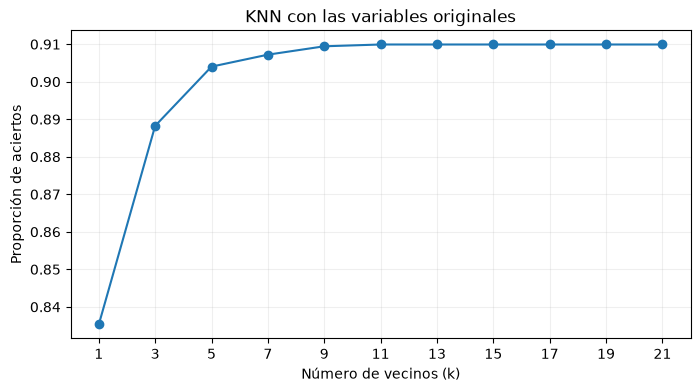

,Proporción de aciertos
k,
1,0.835300
3,0.888233
5,0.904018
7,0.907207
9,0.909439
11,0.909917
13,0.909917
15,0.909917
17,0.909917


In [19]:
K = np.arange(1, 22, 2)  # Mantiene los once valores impares del recorrido.
aciertos_originales = barrido_vecinos(vecinos_originales, y_test_knn, K)  # No repite la búsqueda.
dibujar_barrido(aciertos_originales, "KNN con las variables originales")
aciertos_originales  # Resultados exploratorios de evaluación/validación, no de selección independiente.

### Lectura de la referencia y del barrido

La clase mayoritaria de entrenamiento es **0**. Predecir siempre permanencia acierta el **90,99 %** de los registros reservados, pero no detecta ninguna baja. El 1-NN original (83,53 %) ni siquiera supera esa referencia global.

En el barrido, el acierto sube de **83,53 %** con `k=1` a **90,40 %** con `k=5` y alcanza una meseta de **90,99 %** entre `k=11` y `k=21`. Igualar la referencia no demuestra que se haya aprendido a anticipar bajas: hay que mirar sus errores por clase.

**Cautela de selección:** esa meseta procede de los mismos registros consultados repetidamente. La curva explica cómo cambia el voto al suavizarlo; no justifica anunciar un `k` óptimo ni un acierto futuro independiente.

#### Widget: explicar un caso con sus vecinos

Cambia `k` y la **posición** del registro reservado. `iloc` usa esa posición; el índice mostrado conserva la etiqueta original. La tabla identifica los primeros `k` vecinos de entrenamiento, sus clases y distancias.

Si hay empates en la distancia límite, el voto uniforme puede incluir vecinos adicionales que no caben en esa tabla de `k` filas. Por eso mostramos también los votos normalizados del caso. Una distancia pequeña no implica certeza ni causalidad; su significado depende de las escalas y la codificación.

La siguiente celda vincula la vista a los datos KNN sin variables globales en el script. **Sin widgets:** una vez ejecutada, llama a `explorar_knn(k=3, cliente=0)` para obtener las mismas tablas de un caso.

In [ ]:
from s6_graficos import explorar_knn as _explorar_knn
from s6_controles import crear_control_knn

explorar_knn = partial(_explorar_knn, ajuste=vecinos_originales,
    X_train=X_train_knn, y_train=y_train_knn, X_test=X_test_knn, reales=y_test_knn)
control_knn = crear_control_knn(explorar_knn, n_clientes=len(test_knn))
display(control_knn)

interactive(children=(IntSlider(value=1, continuous_update=False, description='Vecinos', max=21, min=1, step=2…

#### Micropráctica: proximidad y detección de bajas

Reutiliza `predecir`, `tabla_confusion` y el cálculo de sensibilidad de 1-NN. Completa la celda para **`k=3`** y calcula la proporción de bajas reales detectadas respetando la orientación de la matriz.

Después, consulta `escalas_train_knn.head()` y explica por qué ingresos y una tasa entre 0 y 1 no contribuyen de la misma manera a esta distancia. Compara acierto global y sensibilidad sin escoger un `k` final a partir de estas salidas. Los objetos de la práctica no se usarán para seguir.

In [21]:
try:
    k_bajas_mp = ...  # Completa el número de vecinos pedido; no modifica knn1.
    pred_bajas_mp = vecinos_originales.predecir(k=k_bajas_mp)
    tabla_bajas_mp = tabla_confusion(y_test_knn, pred_bajas_mp)
    sensibilidad_bajas_mp = tabla_bajas_mp.loc[..., ...] / tabla_bajas_mp[...].sum()
    display(tabla_bajas_mp, evaluar(y_test_knn, pred_bajas_mp), sensibilidad_bajas_mp)
    display(escalas_train_knn.head())  # Reutiliza la inspección de escalas de entrenamiento.
except Exception as error:
    print("Micropráctica pendiente: completa k y la clase positiva en los huecos.")
    print(f"Detalle: {type(error).__name__}: {error}")

Micropráctica pendiente: completa k y la clase positiva en los huecos.
Detalle: TypeError: '<=' not supported between instances of 'int' and 'ellipsis'


### 6.1.8. ACP antes de KNN: reducir a una dimensión

**Paso 1:** calcula componentes principales con las entradas en sus unidades originales. **Paso 2:** revisa la varianza de cada componente (*scree plot*). **Paso 3:** conserva **solo CP1**, como en el ejemplo, y aplica la misma máscara de filas a sus coordenadas.

El ACP busca direcciones de alta **varianza de las entradas**, no direcciones que separen mejor `churn`. Una proporción de varianza muy alta no garantiza buena clasificación; al reducir a CP1 se puede perder información de baja varianza útil para detectar bajas.

**Cautela preservada:** `fit_transform` se aplica a la muestra completa. Las coordenadas de los registros reservados participan en la transformación aunque no sus clases. Por ello, las comparaciones con CP1 son **exploratorias** y no una evaluación final independiente. Una evaluación final exigiría aprender la transformación con entrenamiento; no cambiamos aquí el recorrido ni la partición.

[Text(0.5, 0, 'Componente principal'),
 Text(0, 0.5, 'Varianza'),
 Text(0.5, 1.0, 'Scree plot')]

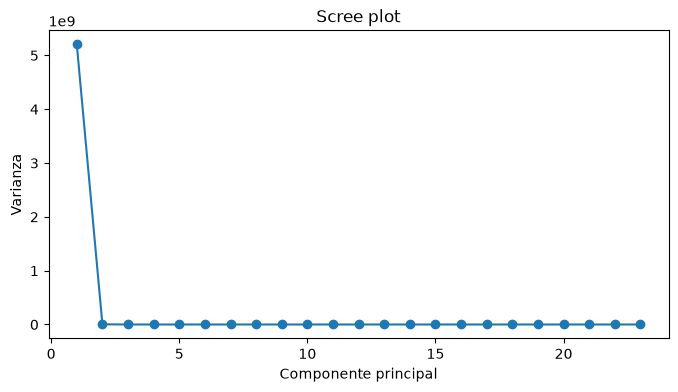

,Varianza,Proporción explicada
1,5.202649e+09,9.992433e-01
2,3.847537e+06,7.389745e-04
3,4.352916e+04,8.360399e-06
4,2.080909e+04,3.996684e-06
5,2.078505e+04,3.992066e-06
6,4.950711e+03,9.508550e-07
7,1.200637e+03,2.305995e-07
8,8.335262e+02,1.600906e-07
9,3.848473e+02,7.391543e-08
10,5.240954e+00,1.006600e-09


In [22]:
# 1. Mantiene el ACP completo y las unidades originales; se ajusta sobre toda d (exploración).
acp_knn = PCA(svd_solver="full")
with threadpool_limits(limits=1):
    componentes_knn = acp_knn.fit_transform(d.drop(columns="churn"))
varianza_componentes = pd.Series(acp_knn.explained_variance_,
                                index=np.arange(1, componentes_knn.shape[1]+1), name="Varianza")

# 2. El scree plot describe varianza, no capacidad de anticipar bajas.
fig, ax = plt.subplots()
ax.plot(varianza_componentes.index, varianza_componentes, "o-")
ax.set(xlabel="Componente principal", ylabel="Varianza", title="Scree plot")
plt.show()
pd.DataFrame({"Varianza": varianza_componentes, "Proporción explicada": acp_knn.explained_variance_ratio_})

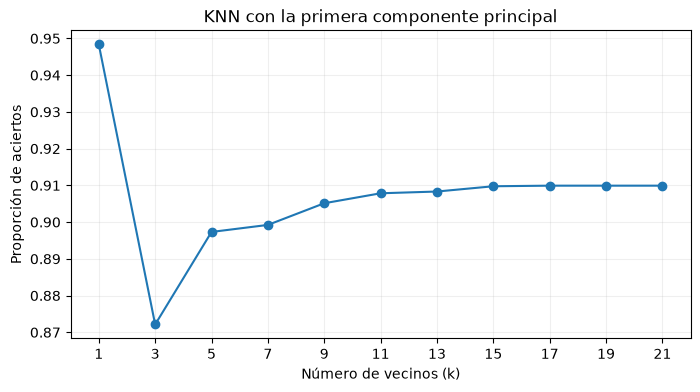

,Proporción de aciertos
k,
1,0.948342
3,0.872130
5,0.897321
7,0.899235
9,0.905134
11,0.907844
13,0.908323
15,0.909758
17,0.909917


In [23]:
# Conserva solo CP1 y exactamente las mismas filas de entrenamiento/evaluación.
cp1_knn = pd.DataFrame({"CP1": componentes_knn[:, 0]}, index=d.index)
train_cp1 = cp1_knn.loc[train_sel_knn]
test_cp1 = cp1_knn.loc[~train_sel_knn]
vecinos_cp1 = Vecinos(train_cp1, y_train_knn, test_cp1)  # Una nueva geometría requiere su propia caché.
aciertos_cp1 = barrido_vecinos(vecinos_cp1, y_test_knn, K)  # Dentro de CP1 reutiliza las distancias.
dibujar_barrido(aciertos_cp1, "KNN con la primera componente principal")
aciertos_cp1

In [24]:
knn_cp1 = vecinos_cp1.predecir(k=1)  # Mantiene el ejemplo de 1-NN en CP1.
tabla_confusion(y_test_knn, knn_cp1)  # La orientación sigue siendo predicción × realidad.
np.mean(knn_cp1.to_numpy() == y_test_knn.to_numpy())  # Acierto exploratorio; ACP vio toda la muestra.

Real,0,1
Predicción,,
0,5539,156
1,168,409


np.float64(0.9483418367346939)

### Lectura del ACP y de 1-NN con CP1

CP1 explica aproximadamente el **99,924 % de la varianza** de las entradas en sus unidades originales. Es coherente con el enorme peso de la escala de ingresos; no significa que explique el 99,924 % de las bajas.

El 1-NN con CP1 acierta el **94,83 %** y detecta **409 de las 565 bajas**, con **156** falsos negativos y **168** falsos positivos. El acierto no mejora monótonamente con `k`: con `k=3` baja al **87,21 %**, y con valores grandes vuelve a acercarse a la referencia mayoritaria.

**Implicación y cautela:** reducir dimensiones cambia qué consideramos próximo y puede alterar mucho el voto. Estas cifras son exploratorias: el ACP vio todas las entradas y la partición puede compartir clientes entre conjuntos. No concluyen que CP1 sea la solución final para clientes nuevos.

#### Widget: explorar el voto en una dimensión

La distancia utiliza **solo CP1**. La altura 0/1 separa las clases para leer el gráfico; `churn` no es una segunda coordenada de distancia.

Los puntos dibujados son una muestra reproducible de hasta **1 000 registros de entrenamiento**. La búsqueda y la matriz utilizan los conjuntos completos: no confundas una muestra para visualizar con una submuestra para ajustar. Cambiar `k` actualiza el voto y las métricas, no el ACP.

La muestra usa explícitamente `SEED` y los colores de Matplotlib. **Sin widgets:** después de la siguiente celda, ejecuta `explorar_cp1(k=3)`; reutiliza la misma caché y la misma muestra para el gráfico.

In [ ]:
from s6_graficos import explorar_cp1 as _explorar_cp1
from s6_controles import crear_control_cp1

explorar_cp1 = partial(_explorar_cp1, ajuste=vecinos_cp1, reales=y_test_knn,
    entrenamiento=train_cp1, clases_train=y_train_knn, semilla=SEED,
    colores=plt.rcParams["axes.prop_cycle"].by_key()["color"])
control_cp1 = crear_control_cp1(explorar_cp1)
display(control_cp1)

interactive(children=(IntSlider(value=1, continuous_update=False, description='Vecinos', max=21, min=1, step=2…

### 6.1.9. Exigir votos mínimos: acierto y cobertura

Con **`k=2`, `minimo=2`**, los dos vecinos deben coincidir para decidir. Si hay empate de distancia y entran vecinos adicionales, el mínimo aumenta con esos vecinos: se mantiene la exigencia de unanimidad del ejemplo.

**Paso 1:** permite una predicción ausente (`NaN`) cuando no se alcanza el mínimo. **Paso 2:** añade la fila **Sin decisión** a la matriz. **Paso 3:** informa del acierto entre clasificados, de la cobertura y del acierto sobre todos los registros.

Un rechazo no es una nueva clase de cliente ni un acierto. Aumentar el mínimo puede dejar menos casos atendidos y elevar el acierto entre los que sí se clasifican. Ese intercambio debe evaluarse en contexto; aquí no elegimos el mínimo mirando el conjunto reservado.

In [26]:
knn_con_rechazo = vecinos_cp1.predecir(k=2, minimo=2)  # Conserva la regla original con unanimidad.
tabla_confusion(y_test_knn, knn_con_rechazo, incluir_rechazos=True)  # No omite los rechazados.
evaluar(y_test_knn, knn_con_rechazo)  # Distingue los tres denominadores.

Real,0,1
Predicción,,
0,5136,146
1,100,87
Sin decisión,471,332


Acierto entre clasificadas               0.955019
Cobertura                                0.871971
Acierto sobre todas las observaciones    0.832749
dtype: float64

### Lectura de la clasificación con rechazos

La regla `k=2`, `minimo=2` clasifica **5 469 de 6 272 registros**: cobertura **87,20 %**. Entre los clasificados acierta el **95,50 %**, pero sobre todos los registros el acierto es **83,27 %**. Quedan **803 sin decisión**, entre ellos **332 bajas reales**.

**Implicación:** el 95,50 % no debe compararse sin más con el 94,83 % de 1-NN en CP1: sus denominadores son diferentes. Un rechazo puede requerir una revisión posterior, no equivale a resolver el caso correctamente. En una campaña de retención interesa saber cuántas bajas detectamos y cuántas dejamos sin atender.

El control siguiente conserva los rangos y el aviso cuando `minimo > k`. **Sin widgets:** tras ejecutarlo, llama a `explorar_rechazo(k=3, minimo=2)` para ver la matriz con **Sin decisión** y las tres métricas, sin cambiar el ejemplo fijo anterior.

In [ ]:
from s6_graficos import explorar_rechazo as _explorar_rechazo
from s6_controles import crear_control_rechazo

explorar_rechazo = partial(_explorar_rechazo, ajuste=vecinos_cp1, reales=y_test_knn)
control_rechazo = crear_control_rechazo(explorar_rechazo)
display(control_rechazo)

interactive(children=(IntSlider(value=2, continuous_update=False, description='Vecinos', max=21, min=1), IntSl…

### 6.1.10. KNN ponderado por kernel y escalas de entrenamiento

Ahora el voto de una clase es la suma de **pesos**, no necesariamente un número entero de vecinos:

$$
\widehat p(c\mid x)=\frac{\sum_{i\in N_k(x)}w_i\,\mathbf{1}(y_i=c)}{\sum_{i\in N_k(x)}w_i}.
$$

El kernel «óptimo» del ejemplo usa el **rango** del vecino y el número de predictores; los kernels triangular y de Epanechnikov usan distancias relativas. Todos producen votos normalizados, no una garantía ni probabilidades calibradas por el mero hecho de sumar 1.

**Paso 1:** divide las entradas por las desviaciones típicas de entrenamiento, aplicando las mismas escalas a las consultas. **Paso 2:** construye una caché para esa nueva geometría. **Paso 3:** compara el ejemplo inicial y el barrido original.

**Cautela:** respecto al primer KNN cambian tanto las escalas como los pesos; no podemos atribuir una diferencia exclusivamente al kernel. Los controles sirven para explorar, no para escoger una configuración y después llamar independiente a su evaluación sobre los mismos registros.

In [28]:
# Aprende las desviaciones con entrenamiento; conserva k=1 y kernel óptimo del ejemplo.
vecinos_kernel = Vecinos(X_train_knn, y_train_knn, X_test_knn, estandarizar=True)
kknn1 = vecinos_kernel.predecir(k=1, kernel="óptimo")
t_kknn1 = tabla_confusion(y_test_knn, kknn1)
t_kknn1
np.mean(kknn1.to_numpy() == y_test_knn.to_numpy())
sensibilidad_kernel1 = t_kknn1.loc[1, 1] / t_kknn1[1].sum()  # No pierde de vista las bajas reales.
sensibilidad_kernel1

Real,0,1
Predicción,,
0,5517,181
1,190,384


np.float64(0.9408482142857143)

np.float64(0.679646017699115)

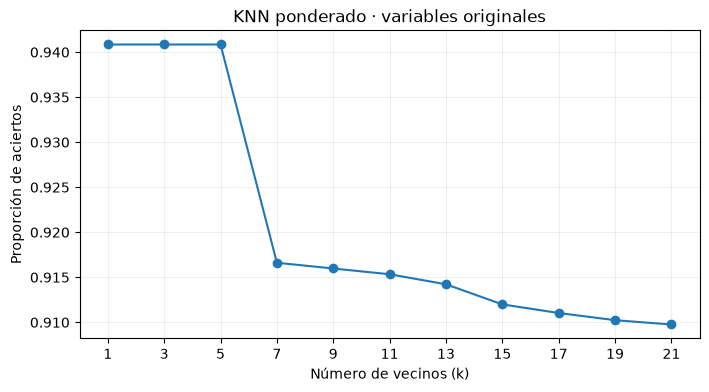

,Proporción de aciertos
k,
1,0.940848
3,0.940848
5,0.940848
7,0.916614
9,0.915976
11,0.915338
13,0.914222
15,0.911990
17,0.911033


In [29]:
aciertos_kernel = barrido_vecinos(vecinos_kernel, y_test_knn, K, kernel="óptimo")  # Reutiliza distancias estandarizadas.
dibujar_barrido(aciertos_kernel, "KNN ponderado · variables originales")
aciertos_kernel  # Comparación exploratoria de los once k originales.

### Lectura de KNN con escalas de entrenamiento

El ejemplo estandarizado con `k=1` acierta el **94,08 %** y detecta **384 de las 565 bajas**: sensibilidad **67,96 %**. Con un solo vecino no hay varios votos que ponderar: la diferencia frente al 1-NN original se debe a la geometría de las escalas, no a que el nombre «óptimo» garantice una mejora.

En el barrido ponderado se mantiene el **94,08 %** para `k=1`, `3` y `5`; después el acierto va aproximándose de nuevo a la referencia mayoritaria. No aumentes `k` suponiendo que siempre mejorará.

**Cautela:** las desviaciones sí proceden de entrenamiento, pero la consulta repetida del conjunto reservado sigue siendo exploración/validación. Igualar escalas tampoco convierte los códigos arbitrarios de categorías en distancias naturales.

#### Kernel con ACP: se conserva el ejemplo `k=2`

Usamos CP1 y sus desviaciones de entrenamiento. Dividir una única coordenada por una constante positiva no cambia el orden de proximidad; sí puede cambiar la votación al pasar de voto uniforme a ponderado y al usar otro `k`.

El ACP sigue aprendido sobre toda la muestra. Las comparaciones con este bloque no son evidencia independiente de mejora. El widget permite ver las clases y los votos sin recalcular las búsquedas.

In [30]:
vecinos_kernel_cp1 = Vecinos(train_cp1, y_train_knn, test_cp1, estandarizar=True)  # Escala aprendida en train_cp1.
kknn_cp1 = vecinos_kernel_cp1.predecir(k=2, kernel="óptimo")  # Mantiene el k=2 original.
tabla_confusion(y_test_knn, kknn_cp1)
np.mean(kknn_cp1.to_numpy() == y_test_knn.to_numpy())

Real,0,1
Predicción,,
0,5539,156
1,168,409


np.float64(0.9483418367346939)

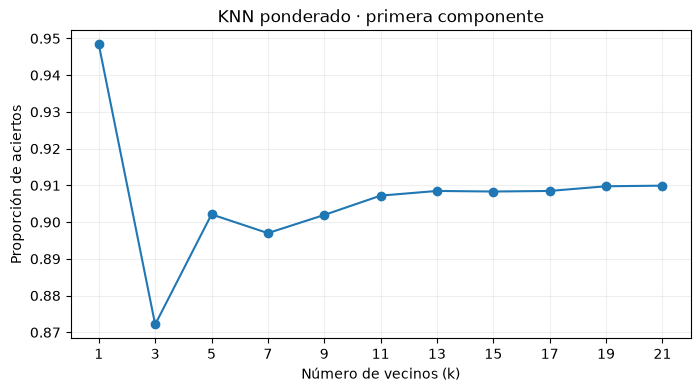

,Proporción de aciertos
k,
1,0.948342
3,0.872130
5,0.902105
7,0.897003
9,0.901945
11,0.907207
13,0.908482
15,0.908323
17,0.908482


In [31]:
aciertos_kernel_cp1 = barrido_vecinos(vecinos_kernel_cp1, y_test_knn, K, kernel="óptimo")  # No vuelve a buscar por k.
dibujar_barrido(aciertos_kernel_cp1, "KNN ponderado · primera componente")
aciertos_kernel_cp1

### Lectura del kernel con CP1

El ejemplo preservado `k=2`, kernel «óptimo», obtiene **94,83 %** y la misma matriz que 1-NN con CP1. En este caso no aporta una mejora observable frente a ese ejemplo. El barrido también muestra resultados inferiores al aumentar `k` en algunos tramos.

Los pesos y el número de vecinos definen otra regla de decisión, pero no crean información nueva. Conserva las cautelas del ACP calculado sobre toda la muestra y distingue **votos normalizados** de certeza.

El control siguiente alterna las dos cachés ya calculadas. **Sin widgets:** después de importarlo, usa `explorar_kernel_knn(datos="CP1", kernel="triangular", k=3)`; muestra las métricas y los votos ponderados sin volver a buscar vecinos.

In [ ]:
from s6_graficos import explorar_kernel_knn as _explorar_kernel_knn
from s6_controles import crear_control_kernel_knn

explorar_kernel_knn = partial(_explorar_kernel_knn,
    originales=vecinos_kernel, cp1=vecinos_kernel_cp1, reales=y_test_knn)
control_kernel_knn = crear_control_kernel_knn(explorar_kernel_knn)
display(control_kernel_knn)

interactive(children=(Dropdown(description='Datos', options=('Originales', 'CP1'), value='Originales'), Dropdo…

#### Micropráctica: cambiar la regla de decisión, no el significado de las métricas

Reutiliza el ejemplo con rechazo para **`k=3`, mínimo de 2 votos** en CP1. Muestra la matriz con **Sin decisión** y las tres métricas de `evaluar`. ¿Sube el acierto entre clasificados a costa de dejar más registros pendientes?

Obtén también los votos del kernel **triangular** con `k=3` en `vecinos_kernel` y comprueba sus sumas por fila. Explica por qué sumar 1 no demuestra calibración ni certeza. No elijas una configuración final con esta micropráctica; sus variables no son dependencias del cuaderno.

In [35]:
try:
    k_rechazo_mp = ...  # Usa el número de vecinos indicado en la práctica.
    minimo_rechazo_mp = ...  # Completa el mínimo de votos pedido.
    pred_rechazo_mp = vecinos_cp1.predecir(k=k_rechazo_mp, minimo=minimo_rechazo_mp)
    display(tabla_confusion(y_test_knn, pred_rechazo_mp, incluir_rechazos=True))
    display(evaluar(y_test_knn, pred_rechazo_mp))  # Lee cobertura además de acierto.
    votos_kernel_mp = vecinos_kernel.probabilidades(k=..., kernel="triangular")
    display(votos_kernel_mp.head(), votos_kernel_mp.sum(axis=1).head())
except Exception as error:
    print("Micropráctica pendiente: completa vecinos y votos mínimos; puedes continuar.")
    print(f"Detalle: {type(error).__name__}: {error}")

Micropráctica pendiente: completa vecinos y votos mínimos; puedes continuar.
Detalle: TypeError: '<=' not supported between instances of 'int' and 'ellipsis'


### 6.1.11. Transformar predictoras: escala y cuantiles

Este complemento completa la comparación de geometrías **sin sustituir los ejemplos anteriores**. Conservamos las mismas filas, la semilla y `k=1`; no escogemos una transformación después de mirar su acierto.

**Paso 1. Estandarizar:** aprende media y desviación con entrenamiento y aplica $z_j=(x_j-\bar x_{j,\mathrm{train}})/s_{j,\mathrm{train}}$ a ambos conjuntos. Restar el mismo centro no cambia las distancias: podemos reutilizar `vecinos_kernel`, que ya dividió por esas desviaciones. Estandarizar no vuelve normal una distribución.

**Paso 2. Transformar por cuantiles:** aprende la distribución acumulada de cada entrada en entrenamiento y aproxima $z_j=\Phi^{-1}(\widehat F_{j,\mathrm{train}}(x_j))$. El orden de cada variable se conserva, pero las separaciones cambian de forma no lineal; los extremos se acotan numéricamente para evitar infinitos. Es otra geometría, no solo un cambio de unidades.

**Paso 3. Evaluar:** compara matriz, acierto global y sensibilidad de **`churn=1`**, con cobertura completa. Se mantiene la advertencia inicial: estas consultas son evaluación/validación exploratoria. Una transformación marginal no establece independencia, ni hace naturales las distancias entre códigos nominales; los muchos empates de indicadores tampoco desaparecen.

In [36]:
# 1. Aprende centros/escalas solo con entrenamiento; churn queda fuera de las entradas.
centros_train_knn = X_train_knn.mean()
desviaciones_train_knn = X_train_knn.std(ddof=1).replace(0, 1)
X_train_z_knn = (X_train_knn - centros_train_knn) / desviaciones_train_knn
X_test_z_knn = (X_test_knn - centros_train_knn) / desviaciones_train_knn
pd.DataFrame({"Media de z en entrenamiento": X_train_z_knn.mean(),
              "Desviación de z en entrenamiento": X_train_z_knn.std(ddof=1)}).head()

# 2. Centrar ambos conjuntos igual no altera las distancias de la caché ya estandarizada.
pred_z_knn = vecinos_kernel.predecir(k=1, kernel="óptimo")
t_z_knn = tabla_confusion(y_test_knn, pred_z_knn)
t_z_knn
evaluar(y_test_knn, pred_z_knn)
t_z_knn.loc[1, 1] / t_z_knn[1].sum()  # Sensibilidad: bajas detectadas / bajas reales.

,Media de z en entrenamiento,Desviación de z en entrenamiento
age,1.844428e-16,1.0
annualincome,-8.008371e-18,1.0
calldroprate,-3.803976e-17,1.0
callfailurerate,1.801884e-17,1.0
customersuspended,2.052145e-16,1.0


Real,0,1
Predicción,,
0,5517,181
1,190,384


Acierto entre clasificadas               0.940848
Cobertura                                1.000000
Acierto sobre todas las observaciones    0.940848
dtype: float64

np.float64(0.679646017699115)

In [ ]:
from sklearn.preprocessing import QuantileTransformer
# Aprende cuantiles en entrenamiento; conserva índices, columnas y partición.
cuantiles_knn = QuantileTransformer(n_quantiles=min(1000, len(X_train_knn)),
                                   output_distribution="normal", subsample=None, random_state=SEED)
with threadpool_limits(limits=1):
    X_train_q_knn = pd.DataFrame(cuantiles_knn.fit_transform(X_train_knn),
                               index=X_train_knn.index, columns=X_train_knn.columns)
    X_test_q_knn = pd.DataFrame(cuantiles_knn.transform(X_test_knn),
                              index=X_test_knn.index, columns=X_test_knn.columns)
# La nueva geometría requiere una búsqueda; no recalcula los KNN anteriores.
vecinos_cuantiles_knn = Vecinos(X_train_q_knn, y_train_knn, X_test_q_knn, max_k=1)
pred_q_knn = vecinos_cuantiles_knn.predecir(k=1, kernel="óptimo")
t_q_knn = tabla_confusion(y_test_knn, pred_q_knn)
t_q_knn  # Predicción en filas, clase real en columnas.
evaluar(y_test_knn, pred_q_knn)
t_q_knn.loc[1, 1] / t_q_knn[1].sum()
# Compara escalas de ingresos, no porcentajes de bajas explicadas.
pd.DataFrame({"Ingresos originales": X_train_knn["annualincome"].quantile([0, .25, .5, .75, 1]),
              "Ingresos transformados": X_train_q_knn["annualincome"].quantile([0, .25, .5, .75, 1])})

Real,0,1
Predicción,,
0,5566,156
1,141,409


Acierto entre clasificadas               0.952647
Cobertura                                1.000000
Acierto sobre todas las observaciones    0.952647
dtype: float64

np.float64(0.7238938053097345)

,Ingresos originales,Ingresos transformados
0.00,5.00,-5.199338
0.25,60870.50,-0.674154
0.50,123542.50,-0.000942
0.75,186591.25,0.675252
1.00,249987.00,5.199338


### Lectura de las transformaciones

Al estandarizar, las primeras cinco entradas tienen media prácticamente **0** y desviación **1** en entrenamiento; eso describe escala, no normalidad. La caché ya disponible reproduce el **94,08 %** de acierto y **384/565 bajas detectadas (67,96 %)**: centrar no añade información ni requiere una búsqueda nueva.

Con cuantiles aprendidos en entrenamiento, el ejemplo fijo 1-NN obtiene **95,26 %** de acierto, **409/565 bajas detectadas (72,39 %)**, **156 falsos negativos** y **141 falsos positivos**, con cobertura **100 %**. Los ingresos van de **5 a 249 987** en su escala original y aproximadamente de **−5,20 a 5,20** en la transformada; la mediana transformada es cercana a cero.

**Implicación:** cambiar separaciones puede cambiar vecinos y errores. La diferencia observada no autoriza a anunciar una solución óptima: se reutilizan los registros reservados y puede haber clientes compartidos entre conjuntos. Tampoco convierte los indicadores o códigos nominales en variables continuas normales.

#### Micropráctica: aprender una transformación sin consultar las respuestas reservadas

Reutiliza los centros y desviaciones para transformar `annualincome` del conjunto reservado. Completa los huecos y muestra sus cuartiles. ¿Por qué su media de validación no tiene que ser exactamente cero? Compara esa operación lineal con los cuantiles, sin volver a ajustar el transformador ni buscar otro `k`.

In [ ]:
try:
    variable_escala_mp = ...  # Nombre de la variable indicada; no uses churn.
    ingresos_z_mp = (X_test_knn[variable_escala_mp] - centros_train_knn[...]) / desviaciones_train_knn[...]
    display(ingresos_z_mp.quantile([0, .25, .5, .75, 1]))
    display(ingresos_z_mp.mean())  # El centro se aprendió en entrenamiento, no en estas filas.
except Exception as error:
    print("Micropráctica pendiente: completa la variable y reutiliza sus parámetros de entrenamiento.")
    print(f"Detalle: {type(error).__name__}: {error}")

## Ejercicio 6-1 — Practicar KNN con datos bancarios (sin resolver)

**1. Lectura.** Lee `bank-additional-full.csv`, separado por **punto y coma**, desde `DATA_PATH`. Inspecciona tamaño, tipos y frecuencias de la respuesta **`y`** (suscripción: `yes`/`no`). No confundas la respuesta con un predictor ni el número de vecinos con grupos de clustering.

**2. Depuración.** Conserva los apartados originales: **a)** declara el orden de las categorías ordinales; **b)** crea dummies de las nominales; **c)** transforma las entradas a valores numéricos; **d)** elimina **`pdays`**. `to_dummy`, importada a continuación desde [s6_knn.py](s6_knn.py), es una ayuda: no resuelve qué variables son ordinales. `unknown` no es automáticamente un nivel educativo ordenado.

**Pistas separadas:** usa `read_csv` y `head()` para leer; `dtypes` y `value_counts()` para inspeccionar; `to_dummy(..., ordinal=True, orden=...)` si hay un orden defendible; en nominales, la última categoría queda como referencia. Los códigos ordinales no demuestran intervalos iguales. Comprueba ausentes después de codificar: una categoría fuera del orden declarado se convierte en ausente.

Antes de hablar de predicción, declara cuándo estarían disponibles las entradas: `duration` se conoce después de la llamada. Se mantiene el ejercicio original, pero su uso limita una conclusión sobre campañas **antes** de llamar. Las celdas pendientes definen funciones con `pass`; no se llaman ni alimentan el bloque de productos.

In [ ]:
from s6_knn import to_dummy  # Ayuda de codificación; no decide las variables del ejercicio.

In [ ]:
# 1. Leer el archivo bank-additional-full.csv (ejercicio pendiente).
def ejercicio61_lectura():
    # Pista 1: reutiliza DATA_PATH y pd.read_csv; identifica el separador.
    # Pista 2: inspecciona shape, head, dtypes y frecuencias de y antes de transformar.
    pass

In [ ]:
# 2. Preparar las variables y retirar pdays (ejercicio pendiente).
def ejercicio61_preparacion():
    # a. Declara el orden de las ordinales; no asignes unknown a un rango sin justificarlo.
    # b. Usa to_dummy en nominales y reúne indicadores con índices/etiquetas sin duplicados.
    # c. Separa la respuesta y; revisa tipos numéricos, ausentes y escalas de las entradas.
    # d. Elimina pdays. No incorpores la respuesta a la distancia.
    pass

**3. Submuestra y partición.** Selecciona una submuestra reproducible de **10 000 observaciones** y divídela en entrenamiento y conjunto reservado. Conserva `SEED=12345`, documenta la proporción y revisa frecuencias por clase; no presupongas que el tamaño de cada clase será idéntico a su esperanza.

**4. Número de vecinos.** Estudia los valores de `k` del recorrido y una proporción de aciertos adecuada. **Pista de cálculo:** crea una caché `Vecinos` para las entradas elegidas y reutiliza `barrido_vecinos`; no construyas una matriz de todas las distancias ni busques de nuevo para cada `k`.

**Pista de interpretación:** compara con la clase mayoritaria decidida en entrenamiento y calcula sensibilidad de la clase minoritaria (`yes`, o `1` si la codificas así). Justifica escalas, errores y coste, no solo el máximo de la curva. Si eliges `k` con el conjunto reservado, este es **validación**; deja la comprobación final para otro conjunto no usado en la elección. Una mejora de acierto no garantiza detección de suscripciones ni certeza en los votos.

In [ ]:
# 3. Submuestra de 10 000 observaciones y partición (ejercicio pendiente).
def ejercicio61_particion():
    # Pista 1: selección sin reemplazo con SEED; conserva una copia de la tabla preparada.
    # Pista 2: crea una máscara de filas y separa X/y, sin modificar train_knn ni test_knn.
    # Pista 3: informa de tamaños y frecuencias de y a ambos lados de la partición.
    pass

In [ ]:
# 4. Estudiar el número de vecinos (ejercicio pendiente).
def ejercicio61_vecinos():
    # Pista 1: construye Vecinos con la submuestra y sus entradas, con un hilo.
    # Pista 2: reutiliza K y barrido_vecinos; compara acierto con la regla mayoritaria.
    # Pista 3: matriz predicción × realidad y sensibilidad de la clase minoritaria.
    # Concluye con las cautelas de validación, disponibilidad de entradas y codificación.
    pass

## 6.2. Naive Bayes: clasificación de productos

**Pregunta:** dadas las características de un producto, ¿a cuál de las categorías de `target` lo asignamos? En KNN votaban vecinos; en NB se combinan **probabilidad a priori de la clase** y **distribuciones de las entradas dentro de esa clase**. Usamos objetos propios de este bloque para conservar KNN y sus controles.

| Variable | Contenido y papel |
| --- | --- |
| `id` | Identificador; permite localizar el producto, no es una entrada del modelo |
| `feat_1` … `feat_93` | 93 características; el ejemplo las tratará como numéricas |
| `target` | Clase real de producto; respuesta, nunca predictor |

### 6.2.1. Leer e inspeccionar antes de ajustar

**Paso 1:** lee la tabla con separador **`;`** y coma decimal. **Paso 2:** comprueba tamaño, nombres, clases y unicidad del identificador. **Paso 3:** revisa el resumen completo y los ausentes; cero es un valor registrado, no un ausente. Una lectura correcta no demuestra que las características tengan forma gaussiana ni que sean independientes.

In [38]:
# 1. Conserva la tabla original de productos; no sobrescribe d ni la partición KNN.
datos = pd.read_csv(DATA_PATH / "products.csv", sep=";", decimal=",")
datos.shape  # Incluye id y target: no todas las columnas son predictoras.
datos.head()  # Localiza productos y comprueba los nombres de sus características.
pd.Series({"Productos": len(datos), "Clases": datos["target"].nunique(),
           "Identificadores distintos": datos["id"].nunique()})

(43190, 95)

,id,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,feat_10,feat_11,feat_12,feat_13,feat_14,...,feat_80,feat_81,feat_82,feat_83,feat_84,feat_85,feat_86,feat_87,feat_88,feat_89,feat_90,feat_91,feat_92,feat_93,target
0,3,0,0,0,0,0,0,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,2,0,3,0,0,0,0,0,Class_2
1,6,0,0,1,3,0,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,1,0,0,0,1,0,Class_6
2,8,0,0,0,0,0,0,0,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0,0,0,1,0,Class_2
3,9,0,0,0,0,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1,0,0,0,0,Class_5
4,10,0,0,0,0,0,0,0,0,1,0,0,0,0,3,...,0,0,0,0,0,1,4,0,4,0,0,0,0,0,Class_3


Productos                    43190
Clases                           9
Identificadores distintos    43190
dtype: int64

In [ ]:
datos.describe(include="all")  # Centro, dispersión y extremos; target se resume como categoría.
datos["target"].value_counts().sort_index()  # Las clases no tienen necesariamente el mismo tamaño.

In [39]:
# Cuenta ausentes por columna y después cuántas columnas tienen cada recuento.
missings_por_columna = datos.isna().sum()
missings_por_columna.value_counts().sort_index().rename_axis("Valores ausentes").to_frame("Número de columnas")
# Inspecciona el dominio numérico; esto no impone una distribución continua a los recuentos.
valores_productos = datos.drop(columns=["id", "target"])
pd.Series({"Celdas con cero": valores_productos.eq(0).sum().sum(),
           "Todas las entradas no negativas": valores_productos.ge(0).all().all(),
           "Todas las entradas enteras": np.equal(valores_productos, np.floor(valores_productos)).all().all()})

,Número de columnas
Valores ausentes,
0,95


Celdas con cero                    3185067
Todas las entradas no negativas       True
Todas las entradas enteras            True
dtype: object

### Lectura de la tabla de productos

Hay **43 190 productos y 95 columnas**: **93 características**, un identificador y la respuesta, con **9 clases**. Los **43 190 identificadores son distintos**. Las **95 columnas tienen cero ausentes**, pero hay **3 185 067 celdas iguales a cero** entre las características.

Todas las entradas son **enteras no negativas** en estos datos. **Implicación:** los ceros forman parte de la distribución, no deben imputarse como si faltaran. Aplicar una gaussiana continua a recuentos con tanta masa en cero es un supuesto del ejemplo que tendremos que reconocer, no una conclusión del resumen.

La tabla de frecuencias permite ver el desequilibrio de categorías. Una categoría abundante pesará más en el acierto global; por eso seguiremos también la sensibilidad por clase.

### 6.2.2. Premisa de independencia condicional y partición

Naive Bayes supone $p(x_1,\ldots,x_p\mid C=c)=\prod_j p(x_j\mid C=c)$: las entradas son **independientes condicionadas a la clase**. No exige que las características sean independientes al mezclar todas las categorías.

**Paso 1:** excluye `id` y `target` de la matriz de correlaciones. **Paso 2:** extrae solo el triángulo superior, sin diagonal: cada pareja aparece una vez. **Paso 3:** representa sus correlaciones marginales por intervalos. Correlación baja no prueba independencia, y correlación marginal no es correlación dentro de clase.

Estos gráficos describen **toda** la muestra, antes de la partición, como en el recorrido original. Más adelante se conserva su uso en dos filtros exploratorios: aunque no usen `target`, miran las entradas reservadas. Un rendimiento final requeriría aprender también esos filtros exclusivamente con entrenamiento.

In [40]:
# 1. Selecciona únicamente características; id y target no pueden contaminar la correlación.
predictores_nb = datos.columns.difference(["id", "target"], sort=False)
with threadpool_limits(limits=1):
    cor_productos = datos[predictores_nb].corr()  # Descripción de toda la muestra, no filtro final independiente.
# 2. Evita parejas duplicadas y las autocorrelaciones de la diagonal.
cor_pares = cor_productos.to_numpy()[np.triu_indices(len(predictores_nb), k=1)]
intervalos_cor = pd.cut(cor_pares, bins=np.linspace(-1, 1, 21), include_lowest=True)
tabla_cor = pd.Series(intervalos_cor).value_counts(sort=False).rename("Pares")
tabla_cor
pd.Series({"Pares distintos": len(cor_pares),
           "Correlación mínima": np.min(cor_pares), "Correlación máxima": np.max(cor_pares),
           "Pares con correlación positiva > 0,8": np.sum(cor_pares > 0.8)})

(-1.001, -0.9]       0
(-0.9, -0.8]         0
(-0.8, -0.7]         0
(-0.7, -0.6]         0
(-0.6, -0.5]         0
(-0.5, -0.4]         0
(-0.4, -0.3]         0
(-0.3, -0.2]         1
(-0.2, -0.1]        38
(-0.1, 0.0]       1405
(0.0, 0.1]        1978
(0.1, 0.2]         510
(0.2, 0.3]         183
(0.3, 0.4]          87
(0.4, 0.5]          43
(0.5, 0.6]          24
(0.6, 0.7]           6
(0.7, 0.8]           2
(0.8, 0.9]           1
(0.9, 1.0]           0
Name: Pares, dtype: int64

Pares distintos                         4278.000000
Correlación mínima                        -0.203781
Correlación máxima                         0.826507
Pares con correlación positiva > 0,8       1.000000
dtype: float64

In [ ]:
# Cada barra cuenta parejas de características, no productos ni clases.
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(np.arange(len(tabla_cor)), tabla_cor.to_numpy())
ax.set(xticks=np.arange(len(tabla_cor)), xticklabels=[str(x) for x in tabla_cor.index],
       xlabel="Intervalo de correlación marginal", ylabel="Pares de variables", title="Correlaciones entre características")
plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
fig.tight_layout()
plt.show()

#### Separar filas y respuesta

**Paso 1:** retira `id`, manteniendo `target` como respuesta. **Paso 2:** vuelve a fijar `SEED=12345` y asigna cada fila al entrenamiento con probabilidad **0,7**, como en el original; no es una partición estratificada de tamaño exacto. **Paso 3:** separa `X` e `y` y compara recuentos por clase.

No se borra el kernel al comenzar NB: las variables de KNN siguen disponibles. La máscara de productos es distinta de la de clientes. Conservamos el nombre `test_nb`; al consultar sus respuestas para comparar filtros, Laplace o kernel, se usa como **evaluación/validación**, según la advertencia inicial, no como test final independiente.

In [41]:
# 1. Partición original por filas; conserva los índices y no incluye id en el modelo.
d_productos = datos.drop(columns="id")
rng_nb = np.random.default_rng(SEED)
train_sel_nb = rng_nb.choice([False, True], size=len(d_productos), p=[0.3, 0.7])
train_nb = d_productos.loc[train_sel_nb].copy()
test_nb = d_productos.loc[~train_sel_nb].copy()

# 2. target no participa en las densidades, correlaciones de entradas ni distancias.
X_train_nb, y_train_nb = train_nb.drop(columns="target"), train_nb["target"]
X_test_nb, y_test_nb = test_nb.drop(columns="target"), test_nb["target"]
pd.Series({"Entrenamiento": len(train_nb), "Evaluación/validación": len(test_nb)})
frecuencias_nb = pd.DataFrame({"Entrenamiento": y_train_nb.value_counts().sort_index(),
                              "Evaluación/validación": y_test_nb.value_counts().sort_index()}).rename_axis("Clase real")
frecuencias_nb
clase_mayoritaria_nb = y_train_nb.value_counts().idxmax()  # La regla se decide sin mirar y_test_nb.
clase_minoritaria_nb = y_train_nb.value_counts().idxmin()  # Seguiremos también su sensibilidad.
acierto_mayoritaria_nb = y_test_nb.eq(clase_mayoritaria_nb).mean()
pd.Series({"Clase mayoritaria de entrenamiento": clase_mayoritaria_nb,
           "Clase minoritaria de entrenamiento": clase_minoritaria_nb,
           "Acierto de predecir siempre la mayoritaria": acierto_mayoritaria_nb})

Entrenamiento            30186
Evaluación/validación    13004
dtype: int64

,Entrenamiento,Evaluación/validación
Clase real,,
Class_1,961,394
Class_2,7840,3387
Class_3,3914,1680
Class_4,1302,559
Class_5,1299,552
Class_6,6869,2976
Class_7,1398,596
Class_8,4165,1818
Class_9,2438,1042


Clase mayoritaria de entrenamiento             Class_2
Clase minoritaria de entrenamiento             Class_1
Acierto de predecir siempre la mayoritaria    0.260458
dtype: object

### Lectura de correlaciones y partición

Las 93 características forman **4 278 parejas distintas**. Sus correlaciones marginales van aproximadamente de **−0,204 a 0,827**; **3 383** parejas caen entre −0,1 y 0,1, y **solo una** supera 0,8. Esto describe asociación lineal marginal; no demuestra independencia condicional, ni ausencia de relaciones no lineales.

La máscara reproducible deja **30 186 productos en entrenamiento y 13 004 en evaluación/validación**. En entrenamiento, la clase mayoritaria es **`Class_2` (7 840 productos)** y la minoritaria **`Class_1` (961)**. En las filas reservadas hay **3 387** y **394**, respectivamente.

Predecir siempre `Class_2`, elegida con entrenamiento, acierta el **26,05 %** de las filas reservadas y no recupera ninguna de las demás categorías. Esa es una referencia, no un modelo que resuelva la clasificación. NB tendrá que leerse globalmente y por cada clase.

### 6.2.3. Ajustar gaussianas y pasar de priors a posteriores

**Paso 1:** estima una media $\mu_{jc}$ y una desviación típica **muestral** $s_{jc}$ de cada característica dentro de cada clase, usando solo entrenamiento. **Paso 2:** estima el prior $\pi_c=n_c/n_{\mathrm{train}}$. **Paso 3:** combina densidades mediante Bayes y normaliza entre clases:

$$
\widehat p(c\mid x)=\frac{\pi_c\prod_j f_{jc}(x_j)}{\sum_h\pi_h\prod_j f_{jh}(x_j)}.
$$

Las tablas de medias/desviaciones son **parámetros de las distribuciones condicionadas a la clase**, no probabilidades posteriores de los productos. El prior no depende del producto; el posterior sí, porque incorpora sus características. Una densidad en un punto no es una probabilidad de clase y puede ser mayor que 1.

Se conservan las reglas numéricas originales: sumar logaritmos para evitar productos diminutos, normalizar con `logsumexp`, sustituir desviación nula o densidad redondeada a cero por **0,001**, y omitir el factor de una entrada ausente al predecir. No se recorta toda densidad pequeña a 0,001. En esta tabla no hay ausentes; esa regla de predicción no es una imputación para el ajuste.

**Supuesto que debemos reconocer:** las características observadas son recuentos enteros, con muchos ceros, pero el ejemplo aplica gaussianas continuas a todas. Lo mantenemos para aprender y comparar; no afirmamos que esa forma de densidad sea adecuada solo porque el modelo se ejecute.

`BayesGaussiano` se importa de [s6_bayes.py](s6_bayes.py). Los ajustes `fit`, las llamadas a `predict` y `predict_proba`, y las tablas de parámetros siguen visibles en las celdas que los utilizan.

In [ ]:
from s6_bayes import BayesGaussiano  # Medias, desviaciones muestrales y reglas numéricas anteriores.

In [43]:
nb = BayesGaussiano().fit(X_train_nb, y_train_nb)  # Mantiene el ajuste base con las 93 entradas.
nb.clases  # Etiquetas, no números con una distancia entre categorías.
pd.DataFrame({"Frecuencia a priori": nb.recuentos, "Probabilidad a priori": nb.prior})
nb.prior.sum()  # Verifica la normalización; no son aún posteriores de un producto.

array(['Class_1', 'Class_2', 'Class_3', 'Class_4', 'Class_5', 'Class_6',
       'Class_7', 'Class_8', 'Class_9'], dtype=object)

,Frecuencia a priori,Probabilidad a priori
target,,
Class_1,961,0.031836
Class_2,7840,0.259723
Class_3,3914,0.129663
Class_4,1302,0.043133
Class_5,1299,0.043033
Class_6,6869,0.227556
Class_7,1398,0.046313
Class_8,4165,0.137978
Class_9,2438,0.080766


np.float64(0.9999999999999999)

In [ ]:
# Cada pareja variable/clase contiene media y desviación, no una probabilidad posterior.
tablas_nb = pd.concat(nb.tablas, names=["Variable", "Clase"])
tablas_nb  # Conserva todas las tablas; el siguiente control permite leer una sin truncarlas.

#### Widget: inspeccionar parámetros, no intervalos de confianza

Elige una característica y lee sus **nueve medias y desviaciones** de entrenamiento. Las barras representan media ± desviación típica: variabilidad de los productos dentro de clase, **no** error estándar ni intervalo de confianza de la media.

Medias distintas pueden aportar separación, pero una dispersión grande puede producir solapamiento. Las clases son etiquetas; la posición de una barra no implica que `Class_1` esté naturalmente más cerca de `Class_2` que de `Class_9`. Cambiar el selector no vuelve a ajustar el modelo.

**Sin widgets:** ejecutada la siguiente celda, llama a `explorar_tabla_nb(variable="feat_45")`. La vista lee el mismo `nb` base recibido como argumento, sin sobrescribirlo.

In [ ]:
from s6_graficos import explorar_tabla_nb as _explorar_tabla_nb
from s6_controles import crear_control_tabla_nb

explorar_tabla_nb = partial(_explorar_tabla_nb, modelo=nb)
control_tabla_nb = crear_control_tabla_nb(explorar_tabla_nb, variables=predictores_nb)
display(control_tabla_nb)

### 6.2.4. Capacidad predictiva global, por clase y probabilidades

**Paso 1:** predice solo las filas reservadas, con los parámetros aprendidos en entrenamiento. **Paso 2:** cuenta la matriz con **predicción en filas y clase real en columnas**; la diagonal contiene aciertos. **Paso 3:** calcula el acierto global y compáralo con la referencia mayoritaria y la sensibilidad de la clase minoritaria.

NB no rechaza en este recorrido: la cobertura es **1** y cada producto recibe la clase con posterior máximo. Una cifra alta no indica certeza ni elimina confusiones importantes. Si usamos estas salidas para elegir variantes, permanecen como validación, no como test final intacto.

In [44]:
preds_nb = nb.predict(X_test_nb)  # No utiliza y_test_nb para asignar las clases.
t_nb = tabla_confusion(y_test_nb, preds_nb, nb.clases)
p_acierto = np.mean(preds_nb.to_numpy() == y_test_nb.to_numpy())
t_nb  # Predicción × realidad: una columna reúne todos los productos reales de esa clase.
p_acierto
evaluar(y_test_nb, preds_nb)
pd.Series({"Referencia mayoritaria": acierto_mayoritaria_nb,
           "Sensibilidad de la clase minoritaria": t_nb.loc[clase_minoritaria_nb, clase_minoritaria_nb] / t_nb[clase_minoritaria_nb].sum()})

Real,Class_1,Class_2,Class_3,Class_4,Class_5,Class_6,Class_7,Class_8,Class_9
Predicción,,,,,,,,,
Class_1,123,9,3,0,1,117,31,310,46
Class_2,30,2254,797,210,29,42,56,97,61
Class_3,24,350,418,20,4,91,92,109,26
Class_4,23,368,282,246,5,159,66,15,35
Class_5,34,306,116,62,508,105,35,123,80
Class_6,9,7,3,2,2,2187,17,77,29
Class_7,25,65,47,15,0,114,274,152,15
Class_8,16,15,7,1,0,46,14,749,15
Class_9,110,13,7,3,3,115,11,186,735


np.float64(0.5762842202399262)

Acierto entre clasificadas               0.576284
Cobertura                                1.000000
Acierto sobre todas las observaciones    0.576284
dtype: float64

Referencia mayoritaria                  0.260458
Sensibilidad de la clase minoritaria    0.312183
dtype: float64

#### Probabilidades posteriores: leer filas, no solo el color

**Paso 1:** pide el posterior de las nueve clases para cada producto. Cada fila conserva su índice y suma aproximadamente **1**. **Paso 2:** recorre el mapa de los primeros **50 productos** o desplázate por las filas reservadas; no se reordenan ni agrupan por similitud. Las columnas son clases, no características.

El color representa el posterior **bajo los supuestos del modelo**. Con entradas dependientes, NB puede contar evidencia repetida y producir probabilidades extremas. Que una fila sume 1, o que un valor se redondee a 1, no demuestra calibración ni certeza. Compara también la clase elegida con su etiqueta real.

**Sin widgets:** tras ejecutar las dos celdas siguientes, usa `explorar_probabilidades(inicio=0, cantidad=50)`. La vista recibe `probs_nb` ya calculada; mover el tramo no vuelve a predecir ni modifica el modelo.

In [45]:
probs_nb = nb.predict_proba(X_test_nb)  # Parámetros y priors del mismo nb base.
probs_nb.head()
probs_nb.sum(axis=1).head()  # Normalización, no prueba de calibración.
pd.DataFrame({"Clase real": y_test_nb.head(), "Clase predicha": preds_nb.head(),
              "Posterior máximo": probs_nb.max(axis=1).head()})

,Class_1,Class_2,Class_3,Class_4,Class_5,Class_6,Class_7,Class_8,Class_9
0,1.313017e-43,9.891214e-01,2.585889e-05,1.085274e-02,9.952857e-52,1.572663e-44,9.486509e-36,6.010446e-56,2.354155e-33
7,1.408708e-68,9.762401e-01,6.596782e-05,2.369396e-02,1.358649e-156,1.287422e-76,3.808916e-33,2.024775e-79,7.410507e-37
10,9.500991e-27,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.110482e-286,1.748265e-102,1.000000e+00,1.695784e-147
13,4.342322e-22,6.788914e-09,1.000000e+00,4.922705e-85,4.977490e-10,4.748142e-20,1.035763e-10,1.665446e-28,1.315450e-12
19,3.235214e-56,5.113817e-74,8.109935e-82,8.905675e-65,1.578782e-219,1.000000e+00,1.085674e-27,7.827794e-14,9.390922e-39


0     1.0
7     1.0
10    1.0
13    1.0
19    1.0
dtype: float64

,Clase real,Clase predicha,Posterior máximo
0,Class_2,Class_2,0.989121
7,Class_4,Class_2,0.976240
10,Class_8,Class_8,1.000000
13,Class_2,Class_3,1.000000
19,Class_6,Class_6,1.000000


In [ ]:
from s6_graficos import explorar_probabilidades as _explorar_probabilidades
from s6_controles import crear_control_probabilidades

explorar_probabilidades = partial(_explorar_probabilidades, probabilidades=probs_nb, mapa_colores="viridis")
control_probabilidades = crear_control_probabilidades(explorar_probabilidades, n_productos=len(probs_nb))
display(control_probabilidades)

#### Acierto por clase real: sensibilidad (*recall*)

Normalizamos cada **columna** de la matriz: su denominador es el número real de productos de esa clase. La diagonal indica qué fracción recuperamos de cada categoría. No es precisión: esta dividiría por la **fila** de predicciones.

Compara en particular la clase minoritaria decidida en entrenamiento. Un acierto global pondera más las clases abundantes y puede esconder una categoría mal recuperada. Aquí hay nueve clases, sin un único «positivo»; en el bloque de clientes sí fijamos **`churn=1`** como positivo.

Class_1    0.312183
Class_2    0.665486
Class_3    0.248810
Class_4    0.440072
Class_5    0.920290
Class_6    0.734879
Class_7    0.459732
Class_8    0.411991
Class_9    0.705374
Name: Acierto por clase, dtype: float64

<BarContainer object of 9 artists>

[(0.0, 1.0),
 Text(0, 0.5, 'Sensibilidad'),
 Text(0.5, 1.0, 'Acierto por clase real')]

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

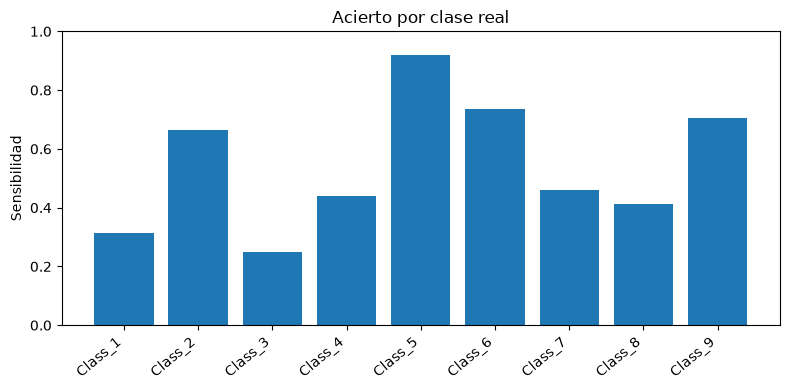

In [46]:
# Divide por totales de columnas: número REAL de productos de cada clase.
acierto_por_clase = pd.Series(np.diag(t_nb.to_numpy()) / t_nb.sum(axis=0).to_numpy(),
                             index=nb.clases, name="Acierto por clase")
acierto_por_clase
fig, ax = plt.subplots()
ax.bar(acierto_por_clase.index, acierto_por_clase)
ax.set(ylim=(0, 1), ylabel="Sensibilidad", title="Acierto por clase real")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fig.tight_layout()
plt.show()

### Lectura del NB base: acierto no es certeza

Los priors de entrenamiento asignan aproximadamente **25,97 %** a `Class_2` y **3,18 %** a `Class_1`; no son las probabilidades de un producto concreto. Las medias y desviaciones describen sus entradas dentro de clase; el posterior combina esos parámetros con los priors.

El NB base acierta **7 494 de 13 004 productos (57,63 %)**, frente al **26,05 %** de la regla mayoritaria, con cobertura **100 %**. La clase minoritaria `Class_1` recupera **123 de 394 (31,22 %)**; quedan **271** productos reales de esa clase asignados a otras. `Class_5` alcanza **92,03 %** de sensibilidad, pero `Class_3` solo **24,88 %**. El promedio global esconde diferencias importantes.

En los ejemplos de posterior, el producto con índice **7**, real `Class_4`, se predice como `Class_2` con **0,97624**; el de índice **13**, real `Class_2`, se predice como `Class_3` con un posterior que se muestra cercano a **1**. **Implicación:** una probabilidad extrema bajo el modelo puede acompañar un error. No es certeza ni una garantía de calibración.

#### Micropráctica: priors, posteriores y clase minoritaria

Inspecciona la **segunda fila reservada** mediante `iloc` y compara su clase real, su posterior y el prior de la clase elegida. Calcula después la sensibilidad de `Class_1` a partir de la matriz. Reutiliza patrones ya ejecutados; no ajustes un modelo distinto ni cambies una decisión para corregir un caso que acabas de observar.

In [ ]:
try:
    posicion_producto_mp = ...  # Segunda fila reservada; iloc cuenta desde cero.
    posterior_producto_mp = probs_nb.iloc[posicion_producto_mp]
    clase_producto_mp = posterior_producto_mp.idxmax()
    display(pd.Series({"Clase real": y_test_nb.iloc[posicion_producto_mp],
                       "Clase predicha": clase_producto_mp,
                       "Posterior elegido": posterior_producto_mp.max(),
                       "Prior de esa clase": nb.prior.loc[clase_producto_mp]}))
    clase_recall_mp = ...  # Clase minoritaria indicada; usa la etiqueta, no su posición.
    recall_nb_mp = t_nb.loc[..., ...] / t_nb[...].sum()  # Reales en columnas.
    display(recall_nb_mp)
except Exception as error:
    print("Micropráctica pendiente: completa posición, clase y denominador del recall.")
    print(f"Detalle: {type(error).__name__}: {error}")

### 6.2.5. Separación exploratoria de las medias: Gini

**Paso 1:** toma las **nueve medias por clase** de cada característica, ya estimadas con entrenamiento. **Paso 2:** mide su desigualdad con

$$
G_j=\frac{\sum_c\sum_h|\mu_{jc}-\mu_{jh}|}{2C\sum_c\mu_{jc}},\qquad C=9.
$$

Si todas las medias son cero, el código devuelve 0. Este índice requiere medias **no negativas**; no es el índice de impureza Gini de un árbol ni una importancia causal. Un valor alto indica medias desiguales, **no** garantiza buen acierto: ignora dispersión, solapamiento, priors y redundancia entre entradas.

**Paso 3:** recorre todas las características en paneles de **nueve gráficos**, conservando las más altas y bajas del ejemplo. La numeración 1–9 del eje identifica `Class_1`–`Class_9` en el orden del ajuste; no define distancias naturales entre categorías.

`gini_medias` se importa de [s6_seleccion.py](s6_seleccion.py); `panel_medias` recibe explícitamente el ajuste base y sus índices Gini. **Sin widgets:** después de las siguientes celdas, llama a `explorar_medias(pagina=2)` para ver la segunda página de nueve características.

In [ ]:
from s6_seleccion import gini_medias
from s6_graficos import panel_medias as _panel_medias

In [ ]:
# Calcula las 93 desigualdades de medias estimadas exclusivamente con entrenamiento.
importancia = nb.medias.apply(gini_medias, axis=0).rename("Gini")
panel_medias = partial(_panel_medias, modelo=nb, importancia=importancia, color="steelblue")
importancia.sort_values(ascending=False).to_frame()  # Orden descriptivo, no lista de causas de target.

,Gini
feat_45,0.817429
feat_84,0.806971
feat_90,0.776089
feat_61,0.774503
feat_19,0.768333
...,...
feat_33,0.274673
feat_65,0.245248
feat_12,0.194692
feat_48,0.191628


In [ ]:
from s6_graficos import explorar_medias as _explorar_medias
from s6_controles import crear_control_medias

explorar_medias = partial(_explorar_medias, predictores=predictores_nb, panel=panel_medias)
control_medias = crear_control_medias(explorar_medias, n_variables=len(predictores_nb))
display(control_medias)

#### Las nueve características con mayor Gini

Compara dónde se concentra su media. Conservamos el nombre `mas_predictoras` del código original, pero su criterio es **desigualdad de medias**, no rendimiento predictivo confirmado. Una entrada muy concentrada en una clase puede ser redundante con otra o tener gran variabilidad interna.

In [ ]:
mas_predictoras = importancia.nlargest(9).index.tolist()  # Conserva las nueve del ejemplo.
mas_predictoras
panel_medias(mas_predictoras, "Mayor desigualdad entre medias de clase")

#### Las nueve características con menor Gini

Busca medias más parecidas entre clases. Un Gini bajo no demuestra que la característica sea inútil: puede haber diferencias de distribución o dispersión que este resumen no captura. No retires columnas solo porque las barras se parezcan sin reconocer qué criterio estás usando.

In [ ]:
menos_predictoras = importancia.nsmallest(9).index.tolist()  # Conserva el extremo bajo, sin alterar nb.
menos_predictoras
panel_medias(menos_predictoras, "Menor desigualdad entre medias de clase")

### 6.2.6. Seleccionar entradas: separación no equivale a mejora

#### Intento original 1: Gini > 0,5

**Paso 1:** observa la distribución de los índices y el umbral fijo **0,5**. **Paso 2:** conserva las entradas que lo superan, calculadas con entrenamiento. **Paso 3:** vuelve a ajustar el mismo NB gaussiano, con la misma respuesta y partición; compara con el modelo base, sin asumir que menos entradas siempre mejoran.

El widget muestra qué ocurre con otros umbrales, incluida la situación sin entradas seleccionadas. Consultar su acierto para escoger un umbral usa `test_nb` como **validación**. No cambiaremos el ejemplo de 0,5 después de ver sus resultados; al cierre compararemos también la sensibilidad minoritaria.

La vista del control ajusta un **modelo local real** con cada subconjunto, sin modificar `nb` ni `nb1`. **Sin widgets:** ejecutadas las celdas de este bloque, usa `explorar_gini(umbral=0.5)`; si ninguna característica supera un umbral, la vista lo indica en lugar de ajustar sin entradas.

In [ ]:
# El histograma cuenta características, no productos; se conserva el corte 0,5.
fig, ax = plt.subplots()
ax.hist(importancia, bins=12, edgecolor="white")
ax.axvline(0.5, color="firebrick", linestyle="--", label="Umbral 0,5")
ax.set(xlabel="Gini de las medias", ylabel="Variables", title="Distribución de la importancia")
ax.legend()
plt.show()

In [49]:
# 1. Selección original con un umbral fijo de desigualdad de medias.
seleccion_gini = importancia.index[importancia > 0.5].tolist()
train1 = train_nb[seleccion_gini + ["target"]]  # La respuesta se conserva en la tabla, no como entrada.
nb1 = BayesGaussiano().fit(train1.drop(columns="target"), y_train_nb)
# 2. predict selecciona solo las columnas aprendidas, aunque X_test_nb conserve las 93.
preds_nb1 = nb1.predict(X_test_nb)
p_acierto1 = np.mean(preds_nb1.to_numpy() == y_test_nb.to_numpy())
len(seleccion_gini)
seleccion_gini
p_acierto1

49

['feat_2',
 'feat_3',
 'feat_4',
 'feat_7',
 'feat_8',
 'feat_9',
 'feat_11',
 'feat_15',
 'feat_17',
 'feat_19',
 'feat_23',
 'feat_26',
 'feat_27',
 'feat_28',
 'feat_29',
 'feat_30',
 'feat_31',
 'feat_34',
 'feat_35',
 'feat_36',
 'feat_39',
 'feat_43',
 'feat_45',
 'feat_46',
 'feat_47',
 'feat_49',
 'feat_50',
 'feat_51',
 'feat_53',
 'feat_56',
 'feat_57',
 'feat_58',
 'feat_59',
 'feat_60',
 'feat_61',
 'feat_68',
 'feat_69',
 'feat_73',
 'feat_75',
 'feat_76',
 'feat_77',
 'feat_78',
 'feat_80',
 'feat_81',
 'feat_82',
 'feat_83',
 'feat_84',
 'feat_90',
 'feat_91']

np.float64(0.45286065825899724)

In [ ]:
from s6_graficos import explorar_gini as _explorar_gini
from s6_controles import crear_control_gini

explorar_gini = partial(_explorar_gini, importancia=importancia, X_train=X_train_nb,
    y_train=y_train_nb, X_test=X_test_nb, reales=y_test_nb, modelo_clase=BayesGaussiano)
control_gini = crear_control_gini(explorar_gini)  # Cada cambio ajusta un modelo local, no modifica nb ni nb1.
display(control_gini)

#### Intento original 2: retirar entradas correlacionadas — sistema 1

**Paso 1:** marca correlaciones **positivas mayores que 0,8**, sin diagonal. **Paso 2:** cuenta cuántas otras entradas cumplen el criterio para cada característica. **Paso 3:** retira **todas** las características con al menos una correlación alta y vuelve a ajustar NB.

Se conserva la regla original: no usa el valor absoluto ni selecciona solo una representante de cada pareja. Retirar ambas puede perder información; decorrelacionar no garantiza independencia condicional ni mejora de clasificación.

Se reutiliza `cor_productos`, calculada sobre **toda la muestra**. Por tanto, el filtro ve entradas reservadas y su comparación es exploratoria. No lo presentaremos como una selección aprendida exclusivamente de entrenamiento.

In [51]:
# 1. Conserva la regla positiva > 0,8; la diagonal no cuenta como otra característica.
cor_altas = cor_productos.gt(0.8).copy()
# La vista .values es de solo lectura en este pandas: modifica la diagonal mediante pandas.
cor_altas = cor_altas.mask(np.eye(len(cor_altas), dtype=bool), False)
numero_cor_altas = cor_altas.sum(axis=0).sort_values(ascending=False)
numero_cor_altas
# 2. Retira todos los extremos de las parejas marcadas, no solo uno por pareja.
retiradas_cor = numero_cor_altas.index[numero_cor_altas >= 1].tolist()
train2 = train_nb.drop(columns=retiradas_cor)  # target no estaba en la matriz de correlaciones.

feat_45    1
feat_39    1
feat_1     0
feat_60    0
feat_68    0
          ..
feat_29    0
feat_28    0
feat_27    0
feat_26    0
feat_93    0
Length: 93, dtype: int64

In [52]:
nb2 = BayesGaussiano().fit(train2.drop(columns="target"), y_train_nb)  # Mismo modelo y filas.
preds_nb2 = nb2.predict(X_test_nb)  # Solo usa las entradas que retuvo fit.
p_acierto2 = np.mean(preds_nb2.to_numpy() == y_test_nb.to_numpy())
retiradas_cor
p_acierto2

['feat_45', 'feat_39']

np.float64(0.5754383266687173)

#### Sistema 2: suma de correlaciones y retirada de 30 entradas

**Paso 1:** suma cada columna de `cor_productos`. La suma conserva el **signo**, por lo que asociaciones negativas y positivas pueden compensarse; no es suma de correlaciones absolutas. Incluye la diagonal 1, común a todas las características, que no cambia su orden.

**Paso 2:** retira las **30** entradas con suma mayor, como en el original. **Paso 3:** ajusta el mismo NB con las restantes y compara su acierto. El número 30 es una regla del recorrido, no un óptimo demostrado. La matriz procede de toda la muestra: mantenemos la cautela de selección exploratoria y evaluamos también posibles pérdidas por clase.

In [53]:
# 1. Mantiene la suma con signo y la retirada fija de 30 entradas.
suma_cor = cor_productos.sum(axis=0).sort_values(ascending=False)
suma_cor
retiradas_suma = suma_cor.head(30).index.tolist()
train3 = train_nb.drop(columns=retiradas_suma)
# 2. No introduce target entre los predictores ni cambia la partición al comparar.
nb3 = BayesGaussiano().fit(train3.drop(columns="target"), y_train_nb)
preds_nb3 = nb3.predict(X_test_nb)
p_acierto3 = np.mean(preds_nb3.to_numpy() == y_test_nb.to_numpy())
retiradas_suma
p_acierto3

feat_22    12.658008
feat_44    12.163543
feat_38    12.153023
feat_54    11.848219
feat_20    11.159028
             ...    
feat_40     0.020797
feat_25    -0.038767
feat_9     -0.055436
feat_14    -1.305984
feat_34    -1.422577
Length: 93, dtype: float64

['feat_22',
 'feat_44',
 'feat_38',
 'feat_54',
 'feat_20',
 'feat_70',
 'feat_18',
 'feat_24',
 'feat_16',
 'feat_66',
 'feat_55',
 'feat_2',
 'feat_49',
 'feat_89',
 'feat_7',
 'feat_35',
 'feat_80',
 'feat_4',
 'feat_76',
 'feat_13',
 'feat_67',
 'feat_62',
 'feat_65',
 'feat_3',
 'feat_28',
 'feat_82',
 'feat_87',
 'feat_31',
 'feat_37',
 'feat_32']

np.float64(0.5864349430944324)

#### Sistema 3: redundancia lineal mediante R²

**Paso 1:** explica cada predictor con **todos los restantes**, sin incluir `target`. **Paso 2:** retira el predictor de R² máximo. **Paso 3:** repite mientras el máximo calculado sea al menos **0,5**. R² alto indica que esa entrada puede reconstruirse linealmente con otras, no que sea irrelevante para la clase.

Se conserva el orden del bucle original: **la última vuelta también retira una variable antes de comprobar la salida**, aunque su máximo ya sea menor que 0,5. `historial_r2` permite reconocer esa retirada; no ajustamos el criterio después de ver el acierto.

El cálculo usa correlaciones de **entrenamiento** para obtener los R² de regresiones con intercepto, evitando ajustar cientos de regresiones sobre 30 186 filas. Si la matriz es singular, utiliza pseudoinversas. Limitamos el álgebra lineal a un hilo. Quitar redundancia lineal tampoco prueba independencia condicional ni garantiza mejor NB.

Las funciones `r2_multiples` y `reducir_por_r2` se importan de [s6_seleccion.py](s6_seleccion.py). La llamada con las entradas de entrenamiento, el límite y el historial de retiradas permanecen visibles a continuación.

In [ ]:
from s6_seleccion import r2_multiples, reducir_por_r2  # Conserva la última retirada por debajo de 0,5.

In [55]:
with threadpool_limits(limits=1):  # Evita exceso de hilos sin cambiar el criterio ni el orden.
    seleccion_r2, historial_r2 = reducir_por_r2(X_train_nb, limite=0.5)

historial_r2  # Cada fila documenta una retirada, incluida la última vuelta por debajo del límite.
len(seleccion_r2)

,Iteración,Retirada,R² máximo,Variables restantes
0,1,feat_3,0.748004,92
1,2,feat_39,0.744743,91
2,3,feat_54,0.663271,90
3,4,feat_72,0.640977,89
4,5,feat_9,0.635564,88
5,6,feat_67,0.631560,87
6,7,feat_84,0.618449,86
7,8,feat_11,0.609861,85
8,9,feat_35,0.565086,84
9,10,feat_24,0.557778,83


77

In [56]:
# 1. Aplica la selección aprendida con entrenamiento a exactamente las mismas filas reservadas.
train4 = train_nb[seleccion_r2 + ["target"]]
test4 = test_nb[train4.columns]
nb4 = BayesGaussiano().fit(train4.drop(columns="target"), y_train_nb)
preds_nb4 = nb4.predict(test4.drop(columns="target"))
# 2. Conserva la matriz completa y el acierto del recorrido original.
t_nb4 = tabla_confusion(y_test_nb, preds_nb4, nb.clases)
p_acierto4 = np.mean(preds_nb4.to_numpy() == y_test_nb.to_numpy())
t_nb4  # Predicción en filas, realidad en columnas.
p_acierto4

Real,Class_1,Class_2,Class_3,Class_4,Class_5,Class_6,Class_7,Class_8,Class_9
Predicción,,,,,,,,,
Class_1,152,11,5,0,2,108,36,322,90
Class_2,36,2305,903,246,30,120,62,116,64
Class_3,24,283,350,26,4,53,114,122,27
Class_4,17,290,211,207,6,175,59,24,34
Class_5,38,384,131,57,507,162,37,134,72
Class_6,16,10,4,3,2,2110,37,114,37
Class_7,20,73,64,16,0,105,226,136,13
Class_8,20,15,7,1,0,57,19,719,23
Class_9,71,16,5,3,1,86,6,131,682


np.float64(0.5581359581667179)

#### Complemento mRMR: relevancia respecto a la clase y redundancia entre entradas

Los tres filtros originales se conservan. Este complemento **no los sustituye ni ajusta otro clasificador**: ilustra un paso de *minimum Redundancy Maximum Relevance* (mRMR). Gini compara medias y R² mide redundancia lineal; mRMR combina **información mutua con `target`** y **redundancia informativa con entradas ya elegidas**.

Con la versión de diferencia y un conjunto seleccionado $S$, la puntuación de una candidata $X_j$ es

$$
\mathrm{mRMR}(j\mid S)=I(X_j;C)-\frac{1}{|S|}\sum_{s\in S}I(X_j;X_s).
$$

Si $S$ está vacío, se empieza por la entrada de mayor $I(X_j;C)$. Aquí las características verificadas son **recuentos enteros**: para esta ilustración calculamos información mutua empírica **discreta**, tratando cada valor como nivel, sin imponer distancias entre códigos. Se mide en **nats**, no es correlación, Gini ni porcentaje de acierto; puede captar asociaciones no lineales.

**Paso 1:** calcula relevancia solo con entrenamiento. **Paso 2:** toma la primera entrada por ese criterio y calcula la redundancia de las restantes con ella. **Paso 3:** inspecciona una siguiente puntuación; no seleccionamos las 20 entradas del ejercicio ni evaluamos un nuevo modelo para subir el acierto. El estimador empírico puede sesgarse con muchos niveles o recuentos escasos, y limitar redundancia por parejas no demuestra independencia condicional.

In [57]:
from sklearn.metrics import mutual_info_score  # Estimación discreta; no requiere otra dependencia.

# 1. Solo entrenamiento: target es la respuesta de relevancia, no una entrada candidata.
with threadpool_limits(limits=1):
    relevancia_mrmr = pd.Series({v: mutual_info_score(X_train_nb[v], y_train_nb)
                                for v in X_train_nb.columns}, name="Información sobre target (nats)")
    primera_mrmr = relevancia_mrmr.idxmax()
    # 2. Ilustra S con una sola entrada; no ejecuta una selección de 20 ni ajusta otro modelo.
    redundancia_mrmr = pd.Series({v: mutual_info_score(X_train_nb[v], X_train_nb[primera_mrmr])
                                 for v in X_train_nb.columns}, name="Redundancia con primera (nats)")
tabla_mrmr = pd.concat([relevancia_mrmr, redundancia_mrmr], axis=1).drop(index=primera_mrmr)
tabla_mrmr["Puntuación mRMR (nats)"] = tabla_mrmr.iloc[:, 0] - tabla_mrmr.iloc[:, 1]
pd.Series({"Primera entrada": primera_mrmr, "Información con target": relevancia_mrmr[primera_mrmr]})
tabla_mrmr.sort_values("Puntuación mRMR (nats)", ascending=False).head(9)
# No añadimos un modelo a la comparación NB: los intentos originales permanecen intactos.

Primera entrada            feat_11
Información con target    0.204322
dtype: object

,Información sobre target (nats),Redundancia con primera (nats),Puntuación mRMR (nats)
feat_34,0.157236,0.013526,0.143710
feat_14,0.170314,0.031499,0.138815
feat_40,0.156502,0.029995,0.126507
feat_60,0.152193,0.041147,0.111046
feat_25,0.179376,0.071743,0.107633
feat_26,0.154432,0.050765,0.103667
feat_15,0.105605,0.020354,0.085251
feat_88,0.103179,0.020098,0.083082
feat_86,0.127020,0.045037,0.081983


### 6.2.7. Laplace y densidades: dos cuestiones diferentes

#### Intento original 3: corrección de Laplace

Para un predictor **categórico** con $L_j$ niveles, Laplace añade un pseudorrecuento $\alpha$ a sus frecuencias condicionadas:

$$
\widehat p(X_j=v\mid C=c)=\frac{n_{jvc}+\alpha}{n_c+\alpha L_j}.
$$

Eso evita probabilidades nulas por categorías no observadas dentro de una clase. **No suaviza una densidad gaussiana**, no elimina correlaciones y no convierte priors en posteriores por sí solo. Que los recuentos se almacenen como enteros no los convierte en categóricos dentro de `BayesGaussiano`: todas las entradas se tratan numéricamente.

Se conserva `laplace=0.1` y el subconjunto **`train3`** (retirada de 30 entradas). El parámetro queda visible en la interfaz pero no modifica sus medias, desviaciones ni priors. La comparación apropiada es con **`nb3`**, no atribuir la diferencia respecto al modelo de 93 entradas a Laplace. La sustitución numérica de densidades cero por 0,001 es otra regla, no esta corrección.

In [58]:
# Conserva laplace=0,1 y las mismas entradas/filas que nb3: no hay tablas categóricas que suavizar.
nb5 = BayesGaussiano(laplace=0.1).fit(train3.drop(columns="target"), y_train_nb)
preds_nb5 = nb5.predict(X_test_nb)
p_acierto5 = np.mean(preds_nb5.to_numpy() == y_test_nb.to_numpy())
nb5.laplace
p_acierto5
pd.Series({"Mismas medias que nb3": nb5.medias.equals(nb3.medias),
           "Mismas desviaciones que nb3": nb5.desviaciones.equals(nb3.desviaciones),
           "Mismas predicciones que nb3": preds_nb5.equals(preds_nb3)})

0.1

np.float64(0.5864349430944324)

Mismas medias que nb3          True
Mismas desviaciones que nb3    True
Mismas predicciones que nb3    True
dtype: bool

#### Intento original 4: densidades kernel en lugar de gaussianas

**Paso 1:** estima una densidad gaussiana kernel **univariante por característica y clase**, usando entrenamiento. **Paso 2:** conserva la regla de Silverman, factor **0,9**, adaptada a la dispersión del grupo; si el rango intercuartílico es cero, se usa la alternativa del código original. **Paso 3:** evalúa densidades por interpolación y combina log-densidades con los mismos priors mediante Bayes.

El ajuste mantiene **512 puntos**, binning lineal y convolución FFT. Son aproximaciones numéricas sobre una rejilla finita: `np.interp` mantiene el valor del extremo fuera de la rejilla. No se sustituye por otro estimador ni se cambia el ancho después de mirar el acierto.

Ahora se usan las **93 entradas** originales, como en `nb`; así comparamos la forma de las densidades con el ajuste base. NB kernel sigue suponiendo **independencia condicional**: no aprende una densidad conjunta ni corrige automáticamente el doble cómputo de evidencia. En recuentos no negativos, el suavizado continuo puede extender densidad a valores negativos; tampoco convierte la altura de una curva en una probabilidad de clase.

`densidad_kernel` y `BayesKernel` se importan de [s6_bayes.py](s6_bayes.py). El ajuste con 512 puntos, la predicción y la matriz de las mismas filas reservadas continúan en el cuaderno.

In [ ]:
from s6_bayes import densidad_kernel, BayesKernel  # Rejilla de 512 puntos, ancho y FFT del ejemplo.

In [ ]:
# Mantiene el ajuste kernel original, con 512 puntos y las 93 características.
with threadpool_limits(limits=1):
    nb6 = BayesKernel(puntos=512).fit(X_train_nb, y_train_nb)
    preds_nb6 = nb6.predict(X_test_nb)
t_nb6 = tabla_confusion(y_test_nb, preds_nb6, nb.clases)
p_acierto6 = np.mean(preds_nb6.to_numpy() == y_test_nb.to_numpy())
t_nb6  # Predicción en filas; clase real en columnas.
p_acierto6

#### Widget: inspeccionar densidades y anchos de banda

Comenzamos con **`feat_45`**, el intervalo **−1 a 1** y una línea de referencia en cero, como en el original. Elige otra característica, una clase o el rango completo. La altura se ajusta al tramo visible para facilitar su lectura; el modelo no se vuelve a entrenar al mover el control.

Cada curva estima $f(x_j\mid C=c)$, **no** $p(C=c\mid x)$: ver cuál es más alta en un punto no basta para clasificar, porque también intervienen las otras 92 entradas y los priors. El área de un intervalo tiene interpretación probabilística bajo la densidad aproximada; la altura en un punto no. Los anchos mostrados ayudan a reconocer diferente suavizado por clase y no se eligen con estas filas reservadas.

**Sin widgets:** ejecutada la siguiente celda, usa `explorar_densidad(variable="feat_45", cerca_de_cero=True, clase="Todas")`, o `cerca_de_cero=False` para el rango completo. La vista recibe las densidades ya ajustadas y no las recorta ni modifica.

In [ ]:
from s6_graficos import explorar_densidad as _explorar_densidad
from s6_controles import crear_control_densidad

explorar_densidad = partial(_explorar_densidad, modelo=nb6,
    colores=plt.rcParams["axes.prop_cycle"].by_key()["color"])
control_densidad = crear_control_densidad(explorar_densidad, variables=predictores_nb, clases=nb6.clases)
display(control_densidad)

### Comparación de las variantes NB ya ajustadas

El cuadro reutiliza las **etiquetas predichas por `nb`, `nb1`…`nb6`**, sobre exactamente los mismos productos reservados. **No ajusta modelos ni cambia parámetros, semillas, entradas seleccionadas o particiones.** `Accuracy` es la proporción global de aciertos; `recall Class_1` divide los aciertos de esa clase por sus **394 productos reales**, no por el número predicho como `Class_1`.

Se conserva el orden del recorrido, **sin ordenar por un ganador**. Gini mide desigualdad de medias; los filtros de correlación y R² intentan reducir redundancia, pero ninguna de esas propiedades garantiza mejor clasificación ni independencia condicional. Los dos filtros que reutilizan correlaciones de toda la muestra siguen siendo exploratorios.

La comparación de Laplace es con **`nb3`**, porque ambos usan las mismas entradas de `train3`: en este NB numérico `laplace=0.1` no modifica las gaussianas. La comparación de las densidades kernel es con el **NB base de 93 entradas**; cambian las densidades univariantes, no la hipótesis de independencia. Estas cifras son de **evaluación/validación**, no de un test final independiente.

El bucle de resumen está en `filas_comparacion_variantes`, de [s6_evaluacion.py](s6_evaluacion.py). Recibe explícitamente modelos, etiquetas y clases reales; comprueba índices y etiquetas antes de contar. La lista de variantes, `filas_comparacion_nb` y `comparacion_nb` siguen disponibles para inspección y ejercicios.

In [ ]:
# Reutiliza modelos y etiquetas ya ajustados; no llama a fit ni escoge una variante.
from s6_evaluacion import filas_comparacion_variantes
variantes_nb = [
    ("Base gaussiano", nb, preds_nb),
    ("Gini > 0,5", nb1, preds_nb1),
    ("Correlación > 0,8: retirar extremos", nb2, preds_nb2),
    ("Suma de correlaciones: retirar 30", nb3, preds_nb3),
    ("R²: retirada original", nb4, preds_nb4),
    ("Laplace 0,1 sobre train3", nb5, preds_nb5),
    ("Kernel: 512 puntos", nb6, preds_nb6),
]
reales_class1_nb = y_test_nb.eq("Class_1")
assert int(reales_class1_nb.sum()) == 394
filas_comparacion_nb = filas_comparacion_variantes(variantes_nb, y_test_nb, clase_minoritaria="Class_1")
comparacion_nb = pd.DataFrame(filas_comparacion_nb).set_index("Variante")
display(comparacion_nb.round({"Accuracy (%)": 2, "Recall Class_1 (%)": 2}))
assert preds_nb5.equals(preds_nb3), "Laplace no debe cambiar este ajuste numérico."
nombre_variante_nb, modelo_variante_nb, etiquetas_variante_nb = variantes_nb[-1]
aciertos_variante_nb = etiquetas_variante_nb.eq(y_test_nb)  # Conserva la última fila para inspeccionarla.

,Entradas,Aciertos / 13004,Accuracy (%),Recuperados Class_1 / 394,Recall Class_1 (%)
Variante,,,,,
Base gaussiano,93,7494,57.63,123,31.22
"Gini > 0,5",49,5889,45.29,74,18.78
"Correlación > 0,8: retirar extremos",91,7483,57.54,125,31.73
Suma de correlaciones: retirar 30,63,7626,58.64,110,27.92
R²: retirada original,77,7258,55.81,152,38.58
"Laplace 0,1 sobre train3",63,7626,58.64,110,27.92
Kernel: 512 puntos,93,2318,17.83,1,0.25


### Lectura del cuadro: no hay una mejora única

Las cifras se han obtenido con los **modelos, parámetros y partición conservados**, no con una selección posterior de un ganador:

- **Gini > 0,5:** retiene **49 entradas**; el acierto es **45,29 %** y el recall de `Class_1`, **18,78 % (74/394)**. La desigualdad de medias no garantizó una mejora respecto al NB base (**57,63 % / 31,22 %**).
- **Correlación > 0,8:** quedan **91 entradas**; acierto **57,54 %** y recall **31,73 % (125/394)**. El acierto global apenas cambia y se recuperan dos productos minoritarios más; esto no demuestra independencia condicional.
- **Retirar 30 por suma de correlaciones:** quedan **63 entradas**; el acierto sube a **58,64 %**, pero el recall baja a **27,92 % (110/394)**: se recuperan **13 productos minoritarios menos** que con el modelo base. Es el ejemplo concreto de por qué accuracy y recall no deben confundirse.
- **Retirada original por R²:** quedan **77 entradas**; acierto **55,81 %** y recall **38,58 % (152/394)**. Recupera **29 productos minoritarios más** que el NB base, aunque el acierto global disminuye. El criterio y su última retirada se mantienen, sin reajustarlos por este resultado.
- **Laplace 0,1 sobre `train3`:** reproduce **exactamente las predicciones** de `nb3`, y por tanto **58,64 % / 27,92 %**. No hay efecto de Laplace sobre las gaussianas numéricas; la diferencia con el NB base procede del subconjunto de entradas, no del pseudorrecuento.
- **NB kernel, 512 puntos y 93 entradas:** acierta **2 318/13 004 (17,83 %)** y recupera **1/394 de `Class_1` (0,25 %)**. Con las reglas y aproximaciones numéricas de este ejemplo, queda incluso por debajo de la referencia mayoritaria (**26,05 %**). Estimar densidades más flexibles no garantizó mejorar la clasificación; estas cifras por sí solas no identifican una causa única del mal rendimiento.

**Conclusión de evaluación:** se observan compromisos distintos entre acierto global y recuperación minoritaria, no una validación automática de los supuestos. Son comparaciones de **evaluación/validación**; los filtros de correlación que vieron toda la muestra siguen siendo exploratorios. No se escoge un ganador por estas respuestas ni se presentan las cifras como rendimiento de un test final intacto.

## Ejercicio 6-2 — KNN y combinación con NB (sin resolver)

**1. Reducir a 20 entradas y comparar KNN.** Reduce el número de variables predictoras a **20** y aplica KNN con diferentes números de vecinos. ¿Mejora la capacidad predictiva medida mediante la proporción de aciertos? Conserva la partición **`train_nb`/`test_nb`**, la respuesta completa y las nueve clases.

**Pista A — selección:** usa un criterio de entrenamiento de los estudiados y explica qué mide; no incluyas `target` ni `id`. Gini no es información mutua y un filtro de correlación no demuestra independencia. No ejecutes una selección de 20 entradas solo porque dé la mejor cifra reservada.

**Pista B — cálculo:** crea objetos distintos de los KNN de clientes; aplica las mismas escalas de entrenamiento a ambas tablas, busca una sola vez con un hilo y reutiliza la caché para varios `k`. Trabaja con las 30 186 filas de entrenamiento y las 13 004 reservadas; no materialices todas las distancias.

**Pista C — lectura:** compara acierto global, matriz **predicción × realidad**, referencia mayoritaria y sensibilidad de `Class_1`. Si el barrido sirve para escoger `k`, informa que usaste validación. La función pendiente no se llama al ejecutar el cuaderno.

In [ ]:
# 1. Seleccionar 20 predictores, ajustar KNN y estudiar el acierto (sin resolver).
def ejercicio62_seleccion_y_knn():
    # A. Selección y escalas aprendidas con entrenamiento; conserva X/y e índices de productos.
    # B. Usa un objeto Vecinos distinto y barrido_vecinos para reutilizar distancias.
    # C. Evalúa la misma partición: acierto global y sensibilidad minoritaria, no solo la curva.
    pass

**2. Promediar probabilidades de KNN y Naive Bayes.** Obtén probabilidades de clase con KNN y promédialas con las de NB. Asigna cada producto a la clase con mayor probabilidad media. ¿Mejora la proporción de aciertos? **Tiempo orientativo: 15 minutos.**

**Pista A — objetos:** `Vecinos.probabilidades` aporta votos normalizados y `probs_nb` contiene los posteriores del NB base. Deben corresponder a **los mismos productos reservados**; no mezcles probabilidades de clientes con productos ni de particiones distintas.

**Pista B — alineación:** compara los índices y las columnas de clase; reordena explícitamente por **índice de producto y etiqueta de clase** antes de promediar. Comprueba sumas por fila. Dos matrices de la misma forma pueden estar desalineadas.

**Pista C — decisión y evaluación:** toma la clase de mayor media y usa `tabla_confusion`/`evaluar` con `y_test_nb`; compara también sensibilidad de `Class_1` con ambos componentes. Se mantiene la media propuesta en el original, sin optimizar pesos con estas respuestas. Promediar dos matrices normalizadas no demuestra calibración ni garantiza mejora; si eliges el ensamble por estas cifras, sigue siendo validación.

In [ ]:
# 2. Promediar las probabilidades de KNN y Naive Bayes y evaluar la asignación (sin resolver).
def ejercicio62_promedio():
    # A. Obtén votos de KNN para exactamente X_test_nb, con el mismo orden de productos.
    # B. Alinea índices y columnas con probs_nb; comprueba normalización antes y después.
    # C. Asigna la clase de mayor media; evalúa acierto y sensibilidad de Class_1.
    # Explica qué cambia y qué limitaciones permanecen. No se ajustan pesos aquí.
    pass

## Cierre didáctico — sesión 6

- **KNN y NN con kernel:** clasifican a partir de distancias y vecinos; el voto uniforme y el ponderado no son lo mismo. El número de vecinos y la ponderación conservados en el recorrido cambian la decisión, pero no autorizan a escogerlos por un supuesto test final ya consultado. El **kernel de vecinos** pondera cercanía; el **NB kernel** estima densidades univariantes por clase: son usos diferentes del kernel.
- **Escalas, PCA y transformaciones:** cambiar unidades o distribución de las entradas cambia las distancias. En este recorrido, centros, desviaciones y cuantiles se aprenden con **entrenamiento** y se aplican a las filas reservadas manteniendo índices y respuesta. El **ACP se calculó sobre toda la muestra**, por lo que sus comparaciones conservan esa limitación exploratoria. Una componente de mucha varianza no garantiza separar clases; ni reducir dimensión ni transformar entradas garantiza mejorar el acierto.
- **Naive Bayes:** los **priors** describen frecuencias de entrenamiento; el **posterior** depende del producto y combina esos priors con sus densidades condicionadas a la clase. Gaussianas y densidades kernel mantienen la **independencia condicional**, que no queda demostrada por correlaciones pequeñas. Normalizar posteriores no demuestra certeza ni calibración; Laplace no altera las densidades numéricas de esta implementación.
- **Errores de la clase minoritaria frente a accuracy:** el NB base acierta **7 494/13 004 (57,63 %)**, pero recupera solo **123/394 de `Class_1` (31,22 %)** y confunde los otros **271**. El acierto global y el recall responden a preguntas distintas: una mejora global puede acompañar una pérdida minoritaria. En clientes seguimos `churn=1`; en productos seguimos `Class_1`, sin mezclar respuestas ni particiones.
- **Validación frente a test final:** las filas llamadas `test_knn` o `test_nb`, consultadas al comparar variantes, son **evaluación/validación**. Un test final independiente solo se consulta cuando las decisiones ya están fijadas, y también los filtros deben haberse aprendido sin sus filas. Los filtros NB que usaron correlaciones de toda la muestra conservan su limitación exploratoria. **No se declara un ganador por estas cifras ni se reajusta el recorrido después de verlas.**

**Ejercicios 6-1 y 6-2: siguen sin resolver.** Sus funciones pendientes se conservan; no se ejecuta la selección de 20 entradas, la combinación KNN/NB ni otra solución. El cierre reúne lo observado y sus límites, sin incorporar modelos o metodologías nuevos.